# Time-series analysis of air alerts in Ukraine

**Data** (built by `data_getter.py`, except the last file):

- `data/processed/weekly_alerts.csv`: the series we analyse.
- `data/processed/daily_alerts.csv`: the daily counts it is summed from.
- `data/processed/etryvoga_daily_alerts.csv`: a second, volunteer-run source, used only in section 8.
- `data/text/air_campaign_statements.csv`: hand-collected public statements, used only in section 10.

**What is counted.** `alerts` is the number of air-raid alerts that started in a period (Kyiv time), over the 24 oblasts and Kyiv city. One unbroken period of alert in an oblast is one alert, whether it was declared for the whole oblast or for some of its raions (districts). An alert for a single hromada (municipality) counts only when no wider alert was in force in its oblast.

**Structure.**

- **Sections 1 to 8:** the count of alerts, from raw data to forecast.
- **Section 9:** the same steps for a second measure, `alert_hours` (time under alert). It answers a question raised in section 3.
- **Section 10:** an experiment with news text.
- **Section 11:** conclusions.

In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import ConvergenceWarning, InterpolationWarning
from scipy import stats
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.forecasting.stl import STLForecast
from statsmodels.tsa.forecasting.theta import ThetaModel
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

sns.set_theme(style="whitegrid", context="notebook")

## 1. Daily data

The daily counts, for reference. Days the source log does not fully cover are blanked, so they show as breaks in the line, not as drops.

1,638 days, 15 Mar 2022 to 07 Sep 2026; 7 blanked as incomplete


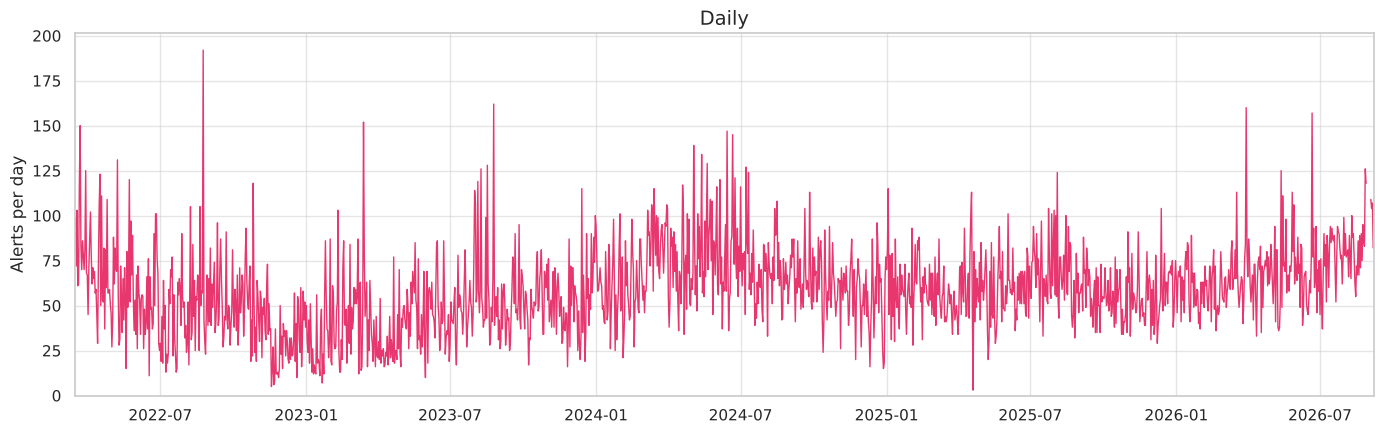

In [2]:
daily = pd.read_csv("data/processed/daily_alerts.csv", parse_dates=["date"], index_col="date")

daily_alerts = daily["alerts"].astype(float)
daily_alerts[daily["incomplete_data"]] = np.nan

print(f"{len(daily):,} days, {daily.index.min():%d %b %Y} to {daily.index.max():%d %b %Y}; "
      f"{int(daily['incomplete_data'].sum())} blanked as incomplete")

fig, ax = plt.subplots(figsize=(14, 4.5))

# matplotlib's plot (styled by seaborn) keeps the breaks at blanked days
ax.plot(daily_alerts.index, daily_alerts.values, color="#e8366f", linewidth=1)

ax.set_title("Daily", fontsize=14)
ax.set_xlabel("")
ax.set_ylabel("Alerts per day")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlim(daily_alerts.index.min(), daily_alerts.index.max())
ax.set_ylim(0, None)
ax.grid(alpha=0.5)

plt.tight_layout()
plt.show()

## 2. Weekly series: the series we analyse

**Why weekly.** Daily counts are mostly noise, with a small day-of-week effect. A week (Monday to Sunday) contains every weekday once, so summing by week removes that effect and averages out much of the noise.

**Which weeks.** Time-series methods need evenly spaced values with no gaps. A week is complete only if the log covers all seven of its days. We use the longest run of consecutive complete weeks.

In [3]:
weekly_file = pd.read_csv("data/processed/weekly_alerts.csv", parse_dates=["week_start"], index_col="week_start")

print(f"{len(weekly_file)} weeks in the file, starting {weekly_file.index.min():%d %b %Y} to {weekly_file.index.max():%d %b %Y}")
print(f"{int(weekly_file['incomplete_data'].sum())} of them incomplete, starting: "
      + ", ".join(weekly_file.index[weekly_file["incomplete_data"]].strftime("%d %b %Y")))

235 weeks in the file, starting 14 Mar 2022 to 07 Sep 2026
4 of them incomplete, starting: 14 Mar 2022, 24 Aug 2026, 31 Aug 2026, 07 Sep 2026


In [4]:
# Label each unbroken run of complete weeks, then keep the longest one.
complete = ~weekly_file["incomplete_data"]
run_id = (complete != complete.shift()).cumsum()
longest_run = complete.groupby(run_id).sum().idxmax()

weekly = weekly_file.loc[run_id == longest_run, "alerts"].asfreq("W-MON")

# The series must be weekly, gap-free and made only of complete weeks.
assert weekly.notna().all()
assert (weekly.index == pd.date_range(weekly.index[0], weekly.index[-1], freq="W-MON")).all()
assert not weekly_file.loc[weekly.index, "incomplete_data"].any()

print(f"{len(weekly)} consecutive weeks, {weekly.index[0]:%d %b %Y} to "
      f"{weekly.index[-1] + pd.Timedelta(days=6):%d %b %Y}")
print(f"{len(weekly_file) - len(weekly)} weeks of the file left out")

231 consecutive weeks, 21 Mar 2022 to 23 Aug 2026
4 weeks of the file left out


In [5]:
# Why weekly: less noise relative to the level, and more memory from one step to the next.
comparison = pd.DataFrame({
    "observations": [int(daily_alerts.notna().sum()), len(weekly)],
    "mean": [daily_alerts.mean(), weekly.mean()],
    "std / mean": [daily_alerts.std() / daily_alerts.mean(), weekly.std() / weekly.mean()],
    "lag-1 autocorrelation": [daily_alerts.autocorr(1), weekly.autocorr(1)],
}, index=["daily", "weekly"])
comparison.round(2)

,observations,mean,std / mean,lag-1 autocorrelation
daily,1631,58.83,0.40,0.36
weekly,231,409.71,0.25,0.71


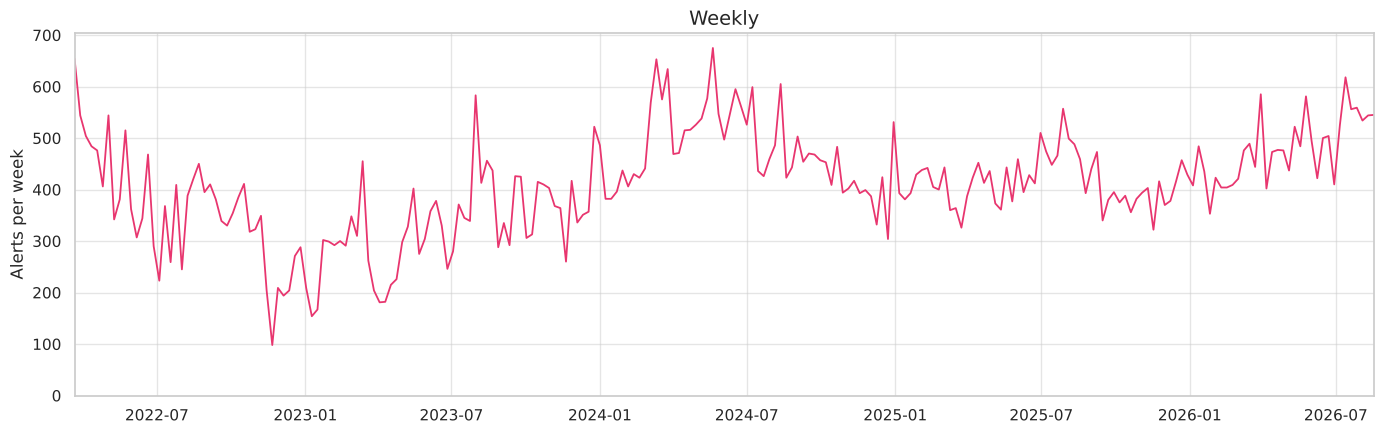

In [6]:
fig, ax = plt.subplots(figsize=(14, 4.5))

sns.lineplot(x=weekly.index, y=weekly.values, color="#e8366f", linewidth=1.3, ax=ax)

ax.set_title("Weekly", fontsize=14)
ax.set_xlabel("")
ax.set_ylabel("Alerts per week")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlim(weekly.index.min(), weekly.index.max())
ax.set_ylim(0, None)
ax.grid(alpha=0.5)

plt.tight_layout()
plt.show()

## 3. Decomposition

We split the series into three parts that add up to it exactly:

**alerts = trend + seasonal + remainder**

The method is STL (seasonal-trend decomposition using LOESS, a local smoother).

- **Additive:** the spread of the series does not grow with its level.
- **`period=52`:** the seasonal cycle is one year.
- **`seasonal=101`, `seasonal_deg=0`:** too few years to see the yearly pattern change, so it is held the same in every year.
- **`trend=81`:** about a year and a half, so the trend carries only movements longer than a year.
- **`robust=False`:** each week of the year has only four or five values; down-weighting outliers would make the pattern copy single years.

In [7]:
PERIOD = 52            # weeks in the seasonal cycle
SEASONAL_WINDOW = 101  # odd; far longer than the data, so the yearly pattern stays fixed
TREND_WINDOW = 81      # odd; about a year and a half

stl = STL(weekly, period=PERIOD, seasonal=SEASONAL_WINDOW, seasonal_deg=0,
          trend=TREND_WINDOW, robust=False).fit()

parts = pd.DataFrame({
    "original": weekly,
    "trend": stl.trend,
    "seasonal": stl.seasonal,
    "remainder": stl.resid,
})

# The three components must add up to the original series.
assert np.allclose(parts["original"], parts[["trend", "seasonal", "remainder"]].sum(axis=1))

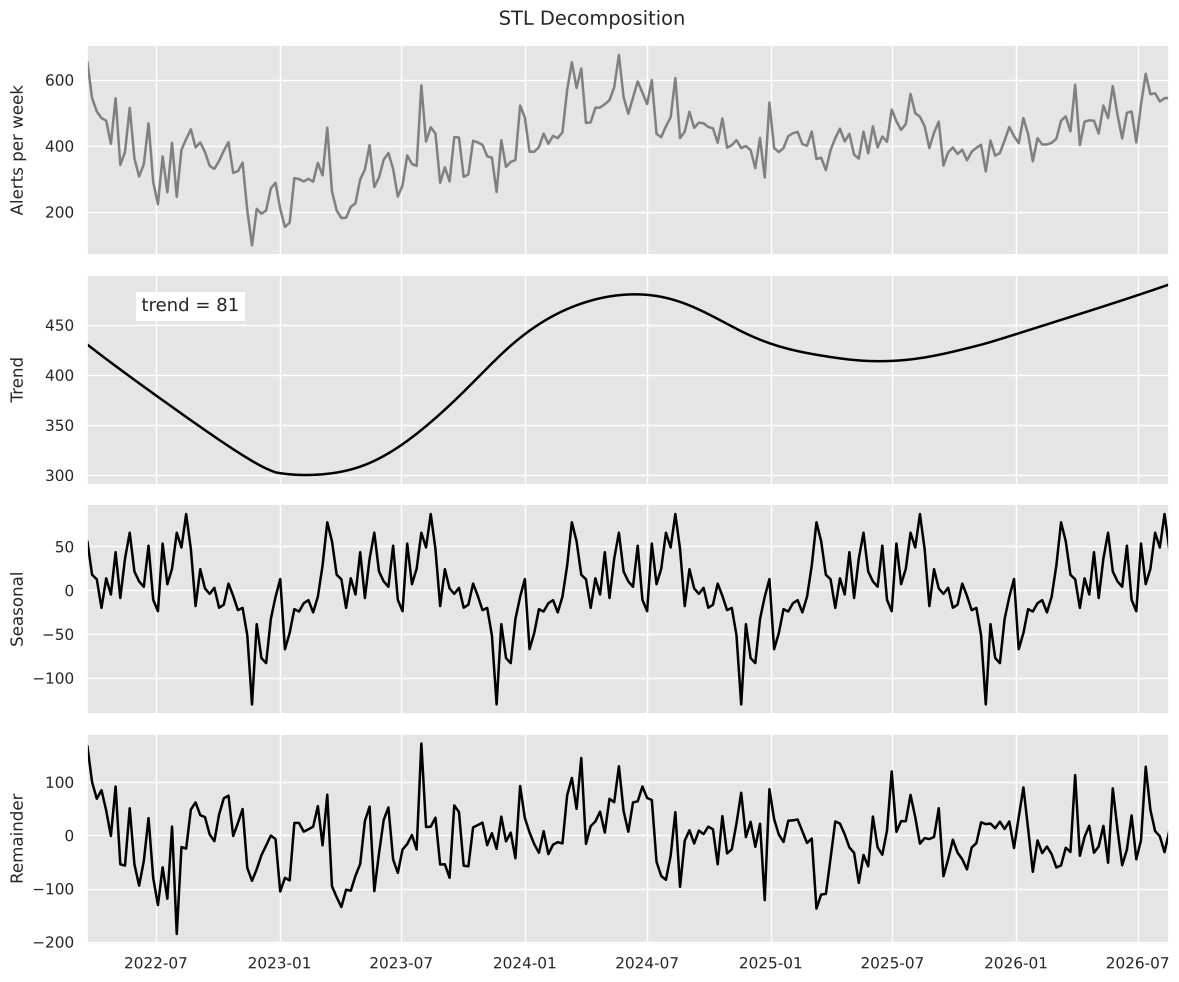

In [8]:
def plot_stl(parts, trend_window, series_label):
    """Four stacked panels: the series, its trend, its seasonal pattern and the remainder."""
    panels = [
        ("original", series_label, "0.5"),
        ("trend", "Trend", "black"),
        ("seasonal", "Seasonal", "black"),
        ("remainder", "Remainder", "black"),
    ]
    with sns.axes_style("darkgrid", {"axes.facecolor": "#e5e5e5"}):
        fig, axes = plt.subplots(len(panels), 1, figsize=(12, 10), sharex=True)
        for ax, (column, label, color) in zip(axes, panels):
            ax.plot(parts.index, parts[column], color=color, linewidth=1.8)
            ax.set_ylabel(label)
            ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
        axes[1].text(0.05, 0.85, f"trend = {trend_window}", transform=axes[1].transAxes,
                     fontsize=13, va="center", bbox={"facecolor": "white", "edgecolor": "none"})
        axes[-1].set_xlim(parts.index.min(), parts.index.max())
        fig.suptitle("STL Decomposition", fontsize=14)
        fig.align_ylabels(axes)
        plt.tight_layout()
        plt.show()


plot_stl(parts, TREND_WINDOW, "Alerts per week")

### Reading the decomposition

- **Strength** of a component: 0 means indistinguishable from noise, 1 means it dominates the remainder. Formula: `1 - Var(remainder) / Var(component + remainder)`.
- **Share of variance:** the component's variance divided by the variance of the series. The shares need not add up to exactly 1.

In [9]:
def strength(component, remainder):
    return max(0.0, 1 - remainder.var() / (component + remainder).var())

components = ["trend", "seasonal", "remainder"]
summary = pd.DataFrame({
    "strength": {
        "trend": strength(parts["trend"], parts["remainder"]),
        "seasonal": strength(parts["seasonal"], parts["remainder"]),
        "remainder": np.nan,
    },
    "share of variance": parts[components].var() / parts["original"].var(),
    "min": parts[components].min(),
    "max": parts[components].max(),
})
summary.round(2)

,strength,share of variance,min,max
trend,0.59,0.33,300.08,490.30
seasonal,0.34,0.17,-130.47,87.09
remainder,NaN,0.33,-185.38,172.33


In [10]:
# The trend at a few dates.
checkpoints = ([parts.index[0]]
               + [parts.index[parts.index >= f"{year}-01-01"][0] for year in range(2023, 2027)]
               + [parts.index[-1]])
print("Trend (alerts per week), week starting:")
print(parts.loc[checkpoints, "trend"].round(0).to_string())
print(f"lowest {parts['trend'].min():.0f} in the week starting {parts['trend'].idxmin():%d %b %Y}, "
      f"highest {parts['trend'].max():.0f} in the week starting {parts['trend'].idxmax():%d %b %Y}")

Trend (alerts per week), week starting:
week_start
2022-03-21    430.0
2023-01-02    302.0
2024-01-01    441.0
2025-01-06    430.0
2026-01-05    442.0
2026-08-17    490.0
lowest 300 in the week starting 06 Feb 2023, highest 490 in the week starting 17 Aug 2026


### A question this trend raises

The trend falls through 2022, recovers, and ends only moderately above where it started. That is flatter than expected for a war in which air attacks are reported to have grown heavier.

Either the expectation is wrong, or a count is the wrong measure: it gives a ten-minute alert and a ten-hour alert the same weight.

**Carried forward:** we continue with the count, which is what we forecast. Section 9 returns to this question by measuring hours under alert.

### How consistent is the seasonal pattern?

The seasonal panel repeats one pattern every year. The table shows what each year actually did: the average distance from trend, by month. A month with the same sign in every year is a dependable part of the pattern; a month whose sign flips is not.

In [11]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

detrended = parts["original"] - parts["trend"]
by_month_year = detrended.groupby([detrended.index.month, detrended.index.year]).mean().unstack()
by_month_year.index = month_names
by_month_year.columns.name = None
by_month_year["same sign every year"] = [
    (row.dropna() > 0).all() or (row.dropna() < 0).all() for _, row in by_month_year.iterrows()
]
by_month_year.round(0)

,2022,2023,2024,2025,2026,same sign every year
Jan,NaN,-75.0,-31.0,-29.0,-24.0,True
Feb,NaN,8.0,-35.0,-2.0,-40.0,False
Mar,171.0,6.0,139.0,-43.0,27.0,False
Apr,50.0,-104.0,24.0,15.0,-6.0,False
May,27.0,9.0,105.0,-26.0,37.0,False
Jun,-34.0,5.0,69.0,27.0,-10.0,False
Jul,-58.0,46.0,11.0,71.0,81.0,False
Aug,22.0,44.0,16.0,43.0,52.0,True
Sep,22.0,-2.0,5.0,-15.0,NaN,False
Oct,29.0,-23.0,-20.0,-51.0,NaN,False


## 4. Autocorrelation of the remainder

If the decomposition captured everything, the remainder would be **white noise**: one week's value would say nothing about the next. The tools:

- **ACF** (autocorrelation function): the correlation of the remainder with itself *k* weeks earlier.
- **PACF** (partial autocorrelation function): the same, after removing what shorter lags already explain.
- **Ljung-Box test:** tests all lags up to *k* at once. A small p-value means the remainder is not white noise.

For white noise, about 95% of the bars fall inside the dashed band, plus or minus 1.96 / sqrt(n).

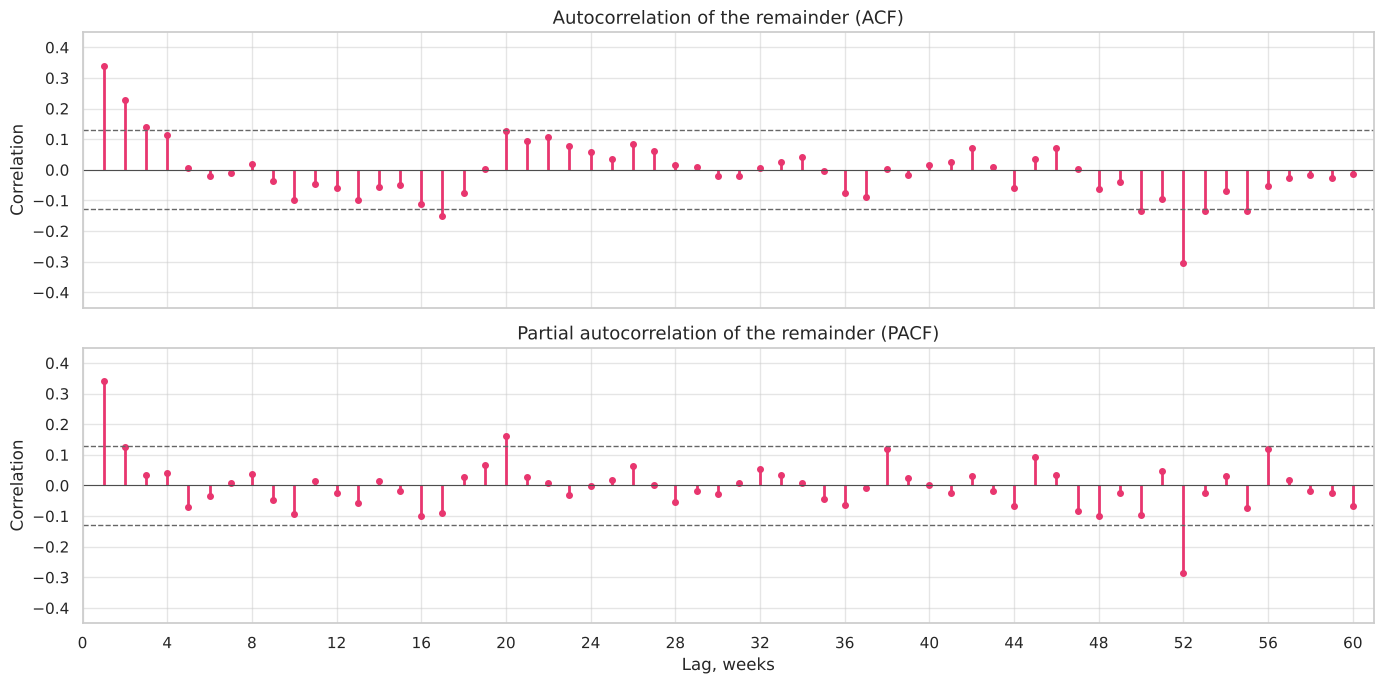

white-noise band: +/-0.129
ACF at lags 1-4: [0.34 0.23 0.14 0.11]
lags with ACF outside the band: [1, 2, 3, 17, 50, 52, 53, 55]


In [12]:
MAX_LAG = 60  # a little over one year, so the 52-week lag is visible


def plot_correlogram(series, kind, title, ax, max_lag=MAX_LAG):
    """Bar chart of the ACF or PACF of a series, with the white-noise band. Returns the values."""
    if kind == "acf":
        values = acf(series, nlags=max_lag, fft=True)
    else:
        values = pacf(series, nlags=max_lag, method="ywm")
    band = 1.96 / np.sqrt(len(series))
    lags = np.arange(1, max_lag + 1)

    ax.vlines(lags, 0, values[1:], color="#e8366f", linewidth=2)
    ax.plot(lags, values[1:], "o", color="#e8366f", markersize=4)
    ax.axhline(0, color="0.3", linewidth=0.8)
    ax.axhline(band, color="0.4", linewidth=1, linestyle="--")
    ax.axhline(-band, color="0.4", linewidth=1, linestyle="--")
    ax.set_title(title, fontsize=13)
    ax.set_ylabel("Correlation")
    ax.set_xlim(0, max_lag + 1)
    ax.set_xticks(range(0, max_lag + 1, 4 if max_lag > 30 else 2))
    ax.grid(alpha=0.5)
    return values


remainder = parts["remainder"]
band = 1.96 / np.sqrt(len(remainder))

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
acf_values = plot_correlogram(remainder, "acf", "Autocorrelation of the remainder (ACF)", axes[0])
plot_correlogram(remainder, "pacf", "Partial autocorrelation of the remainder (PACF)", axes[1])
for ax in axes:
    ax.set_ylim(-0.45, 0.45)
axes[1].set_xlabel("Lag, weeks")

plt.tight_layout()
plt.show()

outside = [k for k in range(1, MAX_LAG + 1) if abs(acf_values[k]) > band]
print(f"white-noise band: +/-{band:.3f}")
print(f"ACF at lags 1-4: {acf_values[1:5].round(2)}")
print(f"lags with ACF outside the band: {outside}")

### What kind of dependence is left?

- **Outside the band:** the first three lags and a cluster around lag 52. With 60 lags, about three stray bars are expected by chance.
- **Lag 52 is a by-product of the decomposition,** not a property of the alerts.
- **Test for the short lags:** we fit AR(1) to the remainder (this week's remainder is a fraction of last week's, plus noise). If what it leaves behind passes the Ljung-Box test, short memory is all that remains. The table gives the test's p-values before and after.

In [13]:
ar1 = ARIMA(remainder, order=(1, 0, 0), trend="n").fit()
ar1_residuals = ar1.resid

print(f"AR(1) coefficient: {ar1.params['ar.L1']:.2f}")
print(f"share of the remainder's variance explained by last week's value: "
      f"{1 - ar1_residuals.var() / remainder.var():.0%}")

# Ljung-Box test: is there autocorrelation anywhere up to lag k, before and after the AR(1) model?
remainder_tests = pd.DataFrame({
    "remainder": acorr_ljungbox(remainder, lags=[4, 8, 13, 26])["lb_pvalue"],
    "remainder after AR(1)": acorr_ljungbox(ar1_residuals, lags=[4, 8, 13, 26], model_df=1)["lb_pvalue"],
})
remainder_tests.index.name = "Ljung-Box p-value, up to lag (weeks)"
remainder_tests.round(3)

AR(1) coefficient: 0.35
share of the remainder's variance explained by last week's value: 12%


,remainder,remainder after AR(1)
"Ljung-Box p-value, up to lag (weeks)",,
4,0.0,0.159
8,0.0,0.540
13,0.0,0.644
26,0.0,0.654


**Carried forward:** the decomposition alone is not a sufficient model. The remainder keeps a memory of about three weeks, so the forecasting model needs an autoregressive (short-memory) term.

## 5. Stationarity and autocorrelation of the series

ARIMA models assume a **stationary** series: its mean, variance and autocorrelation do not change over time. A series with a trend is not stationary. The usual remedy is **differencing**: modelling the week-to-week changes.

Two tests ask the question from opposite sides:

- **ADF** (augmented Dickey-Fuller): a small p-value means stationary.
- **KPSS:** a small p-value means *not* stationary. Its p-values are reported only between 0.01 and 0.10.

We test the series as it is, around a straight-line trend, and after one difference.

In [14]:
def stationarity_tests(series, regression):
    """ADF and KPSS on one series. regression: 'c' = around a constant, 'ct' = around a linear trend."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)  # KPSS p-value outside the tabulated range
        warnings.simplefilter("ignore", FutureWarning)         # notice about a future return type
        adf_stat, adf_p = adfuller(series, regression=regression, autolag="AIC")[:2]
        kpss_stat, kpss_p = kpss(series, regression=regression, nlags="auto")[:2]

    if adf_p < 0.05 and kpss_p > 0.05:
        verdict = "stationary"
    elif adf_p >= 0.05 and kpss_p <= 0.05:
        verdict = "not stationary"
    else:
        verdict = "tests disagree"
    return {"ADF statistic": adf_stat, "ADF p-value": adf_p,
            "KPSS statistic": kpss_stat, "KPSS p-value": kpss_p, "verdict": verdict}


weekly_diff = weekly.diff().dropna()

stationarity = pd.DataFrame({
    "series, around a constant": stationarity_tests(weekly, "c"),
    "series, around a linear trend": stationarity_tests(weekly, "ct"),
    "first difference": stationarity_tests(weekly_diff, "c"),
}).T
stationarity[stationarity.columns[:4]] = stationarity[stationarity.columns[:4]].astype(float).round(3)
stationarity

,ADF statistic,ADF p-value,KPSS statistic,KPSS p-value,verdict
"series, around a constant",-3.346,0.013,0.774,0.010,tests disagree
"series, around a linear trend",-4.300,0.003,0.143,0.056,stationary
first difference,-8.596,0.000,0.235,0.100,stationary


### Autocorrelation of the series and of its first difference

The shapes of the ACF and PACF suggest which model to fit:

- **The ACF decays slowly:** the series needs differencing.
- **After differencing, one spike in the ACF and a fading PACF:** a moving-average term.
- **The reverse:** an autoregressive term.

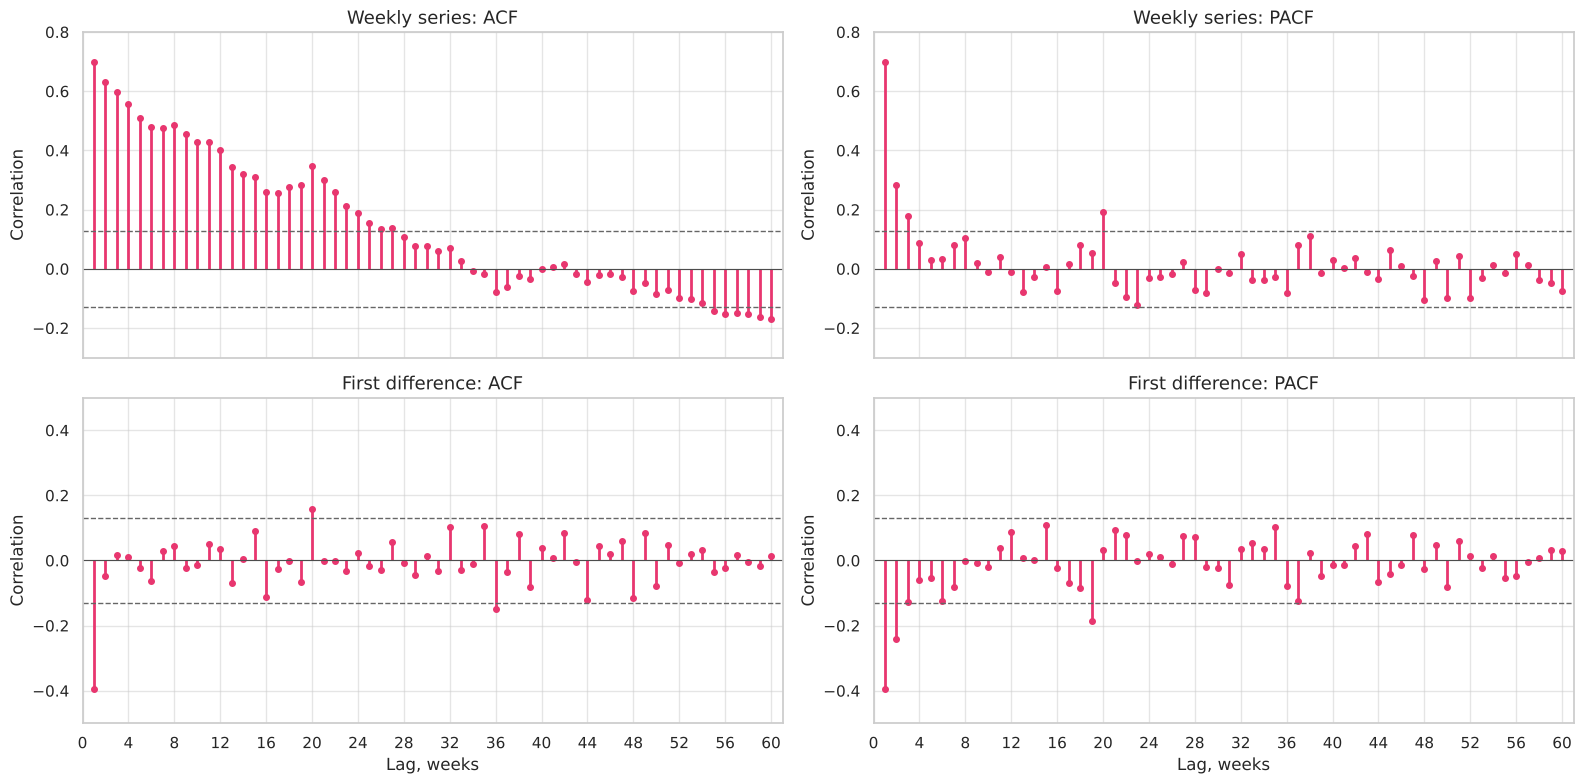

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True)

level_acf = plot_correlogram(weekly, "acf", "Weekly series: ACF", axes[0, 0])
level_pacf = plot_correlogram(weekly, "pacf", "Weekly series: PACF", axes[0, 1])
diff_acf = plot_correlogram(weekly_diff, "acf", "First difference: ACF", axes[1, 0])
diff_pacf = plot_correlogram(weekly_diff, "pacf", "First difference: PACF", axes[1, 1])

for ax in axes[0]:
    ax.set_ylim(-0.3, 0.8)
for ax in axes[1]:
    ax.set_ylim(-0.5, 0.5)
    ax.set_xlabel("Lag, weeks")

plt.tight_layout()
plt.show()

### What we carry into modelling

1. **One difference is needed.** The first difference is stationary by both tests. Around a straight-line trend the series is close to stationary too, so a trend term is the alternative.
2. **Memory is short.** After differencing only lag 1 stands out.
3. **The difference looks like a moving average of order 1:** one negative spike at lag 1 in the ACF and a fading PACF. That is ARIMA(0,1,1), simple exponential smoothing.
4. **No seasonal terms.** There is no spike at 52 weeks.

**Candidates:** a naive forecast (next week equals this week) as the baseline, ARIMA(0,1,1), ARIMA(1,1,1), and a model with a trend, a yearly wave and an AR(1) error.

## 6. Modelling and validation

We fit the candidates, test each on weeks it has not seen, and keep the one that forecasts best.

### Step 1. Hold out the end of the series

A model always looks good on the data it was fitted to. We keep the last 30 weeks as a test set and train on the rest.

train: 201 weeks, 21 Mar 2022 to 25 Jan 2026
test:  30 weeks, 26 Jan 2026 to 23 Aug 2026


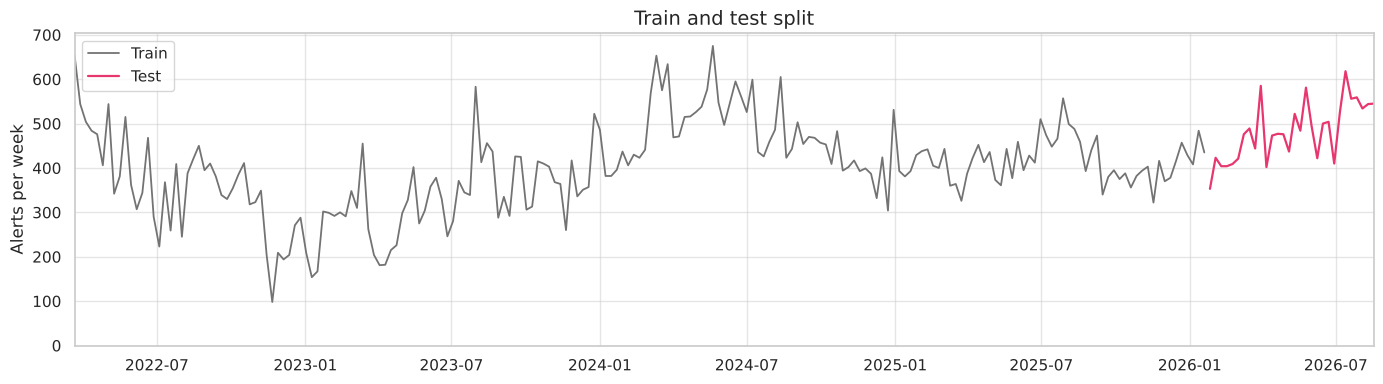

In [16]:
TEST_WEEKS = 30

train = weekly.iloc[:-TEST_WEEKS]
test = weekly.iloc[-TEST_WEEKS:]

print(f"train: {len(train)} weeks, {train.index[0]:%d %b %Y} to {train.index[-1] + pd.Timedelta(days=6):%d %b %Y}")
print(f"test:  {len(test)} weeks, {test.index[0]:%d %b %Y} to {test.index[-1] + pd.Timedelta(days=6):%d %b %Y}")

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(train.index, train.values, color="0.45", linewidth=1.3, label="Train")
ax.plot(test.index, test.values, color="#e8366f", linewidth=1.6, label="Test")
ax.set_title("Train and test split", fontsize=14)
ax.set_ylabel("Alerts per week")
ax.set_xlim(weekly.index.min(), weekly.index.max())
ax.set_ylim(0, None)
ax.grid(alpha=0.5)
ax.legend(loc="upper left", frameon=True)
plt.tight_layout()
plt.show()

### Step 2. Fit the candidates on the training part

In ARIMA(p,d,q): *p* is the number of past values used, *d* the number of times the series is differenced, *q* the number of past forecast errors used.

- **Naive:** next week equals this week. It is the baseline to beat.
- **ARIMA(0,1,1):** the last forecast, corrected by a fraction of its error. It assumes a level that drifts, plus noise.
- **ARIMA(1,1,1):** the same, plus a carry-over of last week's change.
- **Trend + yearly wave + AR(1):** a fitted line and a yearly wave (one sine and one cosine term), plus a fraction of last week's deviation.

In [17]:
MODEL_NAMES = ["Naive", "ARIMA(0,1,1)", "ARIMA(1,1,1)", "Trend + yearly wave + AR(1)"]
not_converged = []  # (model, last week of the data it was fitted on) for fits that did not converge


def yearly_wave(index):
    """One sine and one cosine with a period of a year, as regressors."""
    angle = 2 * np.pi * index.dayofyear / 365.25
    return pd.DataFrame({"sin": np.sin(angle), "cos": np.cos(angle)}, index=index)


def fit_model(name, series):
    """Fit one candidate to a series. The naive model has nothing to fit."""
    if name == "Naive":
        return None
    if name == "ARIMA(0,1,1)":
        model = ARIMA(series, order=(0, 1, 1))
    elif name == "ARIMA(1,1,1)":
        model = ARIMA(series, order=(1, 1, 1))
    else:  # linear trend ("ct" = constant + time) + yearly wave + AR(1) error
        model = ARIMA(series, exog=yearly_wave(series.index), order=(1, 0, 0), trend="ct")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)  # recorded in not_converged instead
        result = model.fit()
    if not result.mle_retvals.get("converged", True):
        not_converged.append((name, series.index[-1]))
    return result


fitted = {name: fit_model(name, train) for name in MODEL_NAMES}

for name in MODEL_NAMES[1:]:
    result = fitted[name]
    print(f"{name}   (AIC {result.aic:.1f})")
    print(result.params.drop("sigma2").round(3).to_string())
    print()

ARIMA(0,1,1)   (AIC 2258.0)
ma.L1   -0.59

ARIMA(1,1,1)   (AIC 2258.2)
ar.L1    0.169
ma.L1   -0.710

Trend + yearly wave + AR(1)   (AIC 2290.4)
const    339.615
drift      0.602
sin       26.533
cos      -36.838
ar.L1      0.640



**Reading the parameters.**

- **`ma.L1`:** in ARIMA(0,1,1) the correction fraction is one plus this coefficient.
- **`drift`:** the fitted rise in alerts per week, from one week to the next.
- **`sin`, `cos`:** the size and timing of the yearly wave.
- **`ar.L1`:** the fraction of last week's deviation that carries over.
- **AIC** (Akaike information criterion): lower is better; it rewards fit and penalises extra parameters. It is comparable only between the two ARIMA models, not with the trend model, which is not differenced.

### Step 3. Validate by walking forward

For each test week we fit every model on all earlier weeks, forecast that one week, and move on. Each forecast uses only what was known at the time, and every model gets 30 forecasts.

In [18]:
def forecast_next(name, history, next_index):
    """Fit on `history` and forecast the following week."""
    if name == "Naive":
        return history.iloc[-1]
    result = fit_model(name, history)
    if name.startswith("Trend"):
        return result.forecast(1, exog=yearly_wave(next_index)).iloc[0]
    return result.forecast(1).iloc[0]


not_converged.clear()
forecasts = pd.DataFrame(index=test.index, columns=MODEL_NAMES, dtype=float)

for step in range(TEST_WEEKS):
    history = weekly.iloc[:len(train) + step]
    next_index = weekly.index[len(train) + step:len(train) + step + 1]
    for name in MODEL_NAMES:
        forecasts.loc[next_index[0], name] = forecast_next(name, history, next_index)

print(f"{TEST_WEEKS} one-week-ahead forecasts per model; "
      f"{len(not_converged)} of {TEST_WEEKS * (len(MODEL_NAMES) - 1)} fits did not converge")

30 one-week-ahead forecasts per model; 0 of 90 fits did not converge


### Step 4. Score the forecasts

- **MAE** (mean absolute error): the average miss, in alerts per week.
- **RMSE** (root mean squared error): like MAE, but large misses count more.
- **MASE:** the model's MAE divided by the naive MAE. Below 1 beats the baseline.
- **Bias:** the average of forecast minus actual. Far from zero means the model is systematically too high or too low.

In [19]:
errors = forecasts.sub(test, axis=0)

scores = pd.DataFrame({
    "MAE": errors.abs().mean(),
    "RMSE": np.sqrt((errors ** 2).mean()),
    "bias": errors.mean(),
})
scores.insert(2, "MASE", scores["MAE"] / scores.loc["Naive", "MAE"])
scores["weeks closer than naive"] = [
    int((errors[name].abs() < errors["Naive"].abs()).sum()) if name != "Naive" else np.nan
    for name in scores.index
]
scores = scores.sort_values("MAE")

best_model = scores.index[0]
print(f"best model by MAE: {best_model}")
scores.round(2)

best model by MAE: ARIMA(0,1,1)


,MAE,RMSE,MASE,bias,weeks closer than naive
"ARIMA(0,1,1)",40.36,57.03,0.75,-8.70,17.0
"ARIMA(1,1,1)",41.52,57.31,0.78,-10.43,19.0
Trend + yearly wave + AR(1),47.61,60.83,0.89,-0.65,18.0
Naive,53.47,70.60,1.00,-3.67,NaN


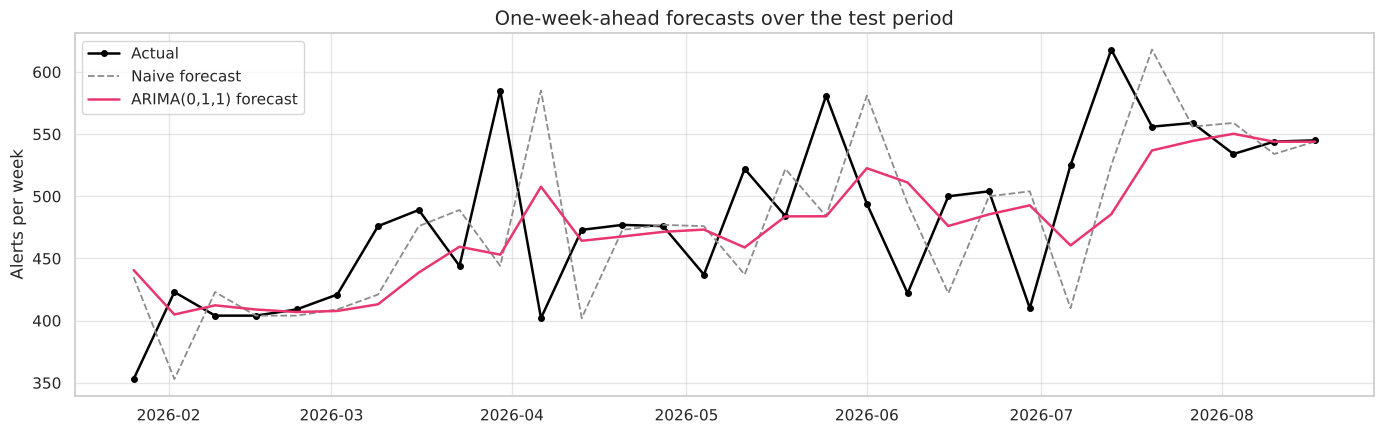

In [20]:
fig, ax = plt.subplots(figsize=(14, 4.5))

ax.plot(test.index, test.values, color="black", linewidth=1.8, marker="o", markersize=4, label="Actual")
ax.plot(forecasts.index, forecasts["Naive"], color="0.55", linewidth=1.3, linestyle="--", label="Naive forecast")
ax.plot(forecasts.index, forecasts[best_model], color="#e8366f", linewidth=1.8, label=f"{best_model} forecast")

ax.set_title("One-week-ahead forecasts over the test period", fontsize=14)
ax.set_ylabel("Alerts per week")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.grid(alpha=0.5)
ax.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()

### Step 5. Check the winner's errors

If the model captured the structure of the series, its residuals are white noise. We use the tools of section 4: the ACF against the white-noise band, and the Ljung-Box test.

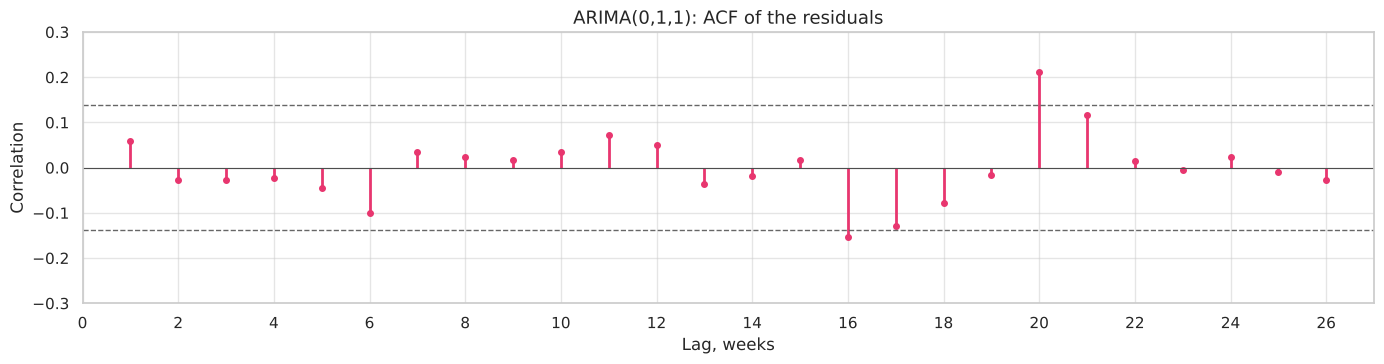

lags with ACF outside the band: [16, 20]
residual standard deviation: 68.0 alerts per week


,statistic,p-value
up to lag (weeks),,
4,1.117,0.773
8,3.990,0.781
13,6.256,0.903
26,30.187,0.217


In [21]:
best_fit = fitted[best_model]
# a differenced model has no real residual for the first week
best_residuals = best_fit.resid.iloc[1:] if "1,1" in best_model else best_fit.resid
n_parameters = len(best_fit.params) - 1  # all estimated parameters except the noise variance

fig, ax = plt.subplots(figsize=(14, 3.8))
residual_acf = plot_correlogram(best_residuals, "acf", f"{best_model}: ACF of the residuals", ax, max_lag=26)
ax.set_ylim(-0.3, 0.3)
ax.set_xlabel("Lag, weeks")
plt.tight_layout()
plt.show()

residual_band = 1.96 / np.sqrt(len(best_residuals))
print(f"lags with ACF outside the band: "
      f"{[k for k in range(1, 27) if abs(residual_acf[k]) > residual_band]}")
print(f"residual standard deviation: {best_residuals.std():.1f} alerts per week")

residual_test = acorr_ljungbox(best_residuals, lags=[4, 8, 13, 26], model_df=min(n_parameters, 3))
residual_test.index.name = "up to lag (weeks)"
residual_test.columns = ["statistic", "p-value"]
residual_test.round(3)

### Step 6. Re-check against a wider set of models

Four candidates and 30 test weeks are a narrow basis. Here the winner faces 14 rivals over the last 104 weeks, among them other ARIMA orders, seasonal models, exponential smoothing and a four-week average.

The last column is a paired test against ARIMA(0,1,1) (a Diebold-Mariano test). A p-value above 0.05 means the two models cannot be told apart.

This cell takes around a minute.

In [22]:
RECHECK_WEEKS = 104


def arima_forecaster(order, trend=None, wave=False, log=False):
    """Build a function that fits one ARIMA variant on a history and forecasts the next week."""
    def forecast(history, next_index):
        series = np.log(history) if log else history
        exog = yearly_wave(history.index) if wave else None
        result = ARIMA(series, exog=exog, order=order, trend=trend).fit()
        prediction = result.get_forecast(1, exog=yearly_wave(next_index) if wave else None)
        mean = prediction.predicted_mean.iloc[0]
        if log:  # mean of a log-normal variable
            mean = np.exp(mean + prediction.var_pred_mean.iloc[0] / 2)
        return mean
    return forecast


def exponential_smoothing_forecaster(**settings):
    def forecast(history, next_index):
        return ExponentialSmoothing(history, **settings).fit().forecast(1).iloc[0]
    return forecast


def stl_arima_forecast(history, next_index):
    """Remove the 52-week pattern with STL, forecast the rest with ARIMA(0,1,1), add the pattern back."""
    model = STLForecast(history, ARIMA, model_kwargs={"order": (0, 1, 1)},
                        period=PERIOD, seasonal=SEASONAL_WINDOW, seasonal_deg=0, robust=False)
    return model.fit().forecast(1).iloc[0]


recheck_models = {
    "Naive": lambda history, next_index: history.iloc[-1],
    "Mean of last 4 weeks": lambda history, next_index: history.iloc[-4:].mean(),
    "ARIMA(0,1,1)": arima_forecaster((0, 1, 1)),
    "ARIMA(0,1,1) + drift": arima_forecaster((0, 1, 1), trend="t"),
    "ARIMA(0,1,1) + yearly wave": arima_forecaster((0, 1, 1), wave=True),
    "ARIMA(0,1,1) on log scale": arima_forecaster((0, 1, 1), log=True),
    "ARIMA(1,1,1)": arima_forecaster((1, 1, 1)),
    "ARIMA(0,1,2)": arima_forecaster((0, 1, 2)),
    "ARIMA(2,1,0)": arima_forecaster((2, 1, 0)),
    "ARIMA(1,0,1) + constant": arima_forecaster((1, 0, 1), trend="c"),
    "Trend + yearly wave + AR(1)": arima_forecaster((1, 0, 0), trend="ct", wave=True),
    "Holt, damped trend": exponential_smoothing_forecaster(trend="add", damped_trend=True),
    "Holt-Winters, 52-week season": exponential_smoothing_forecaster(seasonal="add", seasonal_periods=PERIOD),
    "STL (52 weeks) + ARIMA(0,1,1)": stl_arima_forecast,
    "Theta": lambda history, next_index: ThetaModel(history, period=PERIOD, deseasonalize=False).fit().forecast(1).iloc[0],
}

recheck_start = len(weekly) - RECHECK_WEEKS
recheck_actual = weekly.iloc[recheck_start:]
recheck_forecasts = pd.DataFrame(index=recheck_actual.index, columns=list(recheck_models), dtype=float)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # optimiser notices from 1,500 fits; accuracy below is what counts
    for step in range(RECHECK_WEEKS):
        history = weekly.iloc[:recheck_start + step]
        next_index = weekly.index[recheck_start + step:recheck_start + step + 1]
        for name, forecast in recheck_models.items():
            recheck_forecasts.loc[next_index[0], name] = forecast(history, next_index)

recheck_errors = recheck_forecasts.sub(recheck_actual, axis=0).abs()
reference = recheck_errors["ARIMA(0,1,1)"]

recheck = pd.DataFrame({
    "MAE": recheck_errors.mean(),
    "RMSE": np.sqrt((recheck_errors ** 2).mean()),
})
recheck["MASE"] = recheck["MAE"] / recheck.loc["Naive", "MAE"]
recheck["MAE, last 30 weeks"] = recheck_errors.iloc[-TEST_WEEKS:].mean()
recheck["p-value vs ARIMA(0,1,1)"] = [
    stats.ttest_1samp(recheck_errors[name] - reference, 0).pvalue if name != "ARIMA(0,1,1)" else np.nan
    for name in recheck.index
]
recheck = recheck.sort_values("MAE")

print(f"{RECHECK_WEEKS} test weeks, {recheck_actual.index[0]:%d %b %Y} to "
      f"{recheck_actual.index[-1] + pd.Timedelta(days=6):%d %b %Y}; shortest training set {recheck_start} weeks")
recheck.round(3)

104 test weeks, 26 Aug 2024 to 23 Aug 2026; shortest training set 127 weeks


,MAE,RMSE,MASE,"MAE, last 30 weeks","p-value vs ARIMA(0,1,1)"
"Holt, damped trend",36.472,49.453,0.781,39.959,0.917
"ARIMA(0,1,1) + drift",36.487,49.998,0.782,40.742,0.922
"ARIMA(0,1,1)",36.507,49.825,0.782,40.357,NaN
Mean of last 4 weeks,36.541,49.417,0.783,40.283,0.974
"ARIMA(0,1,1) + yearly wave",36.565,49.640,0.783,40.570,0.905
"ARIMA(1,0,1) + constant",36.707,49.754,0.786,42.796,0.695
Theta,36.884,50.138,0.790,40.636,0.047
"ARIMA(0,1,2)",37.204,50.729,0.797,41.331,0.194
"ARIMA(1,1,1)",37.351,50.772,0.800,41.516,0.125
"ARIMA(2,1,0)",38.194,51.579,0.818,42.461,0.049


### Result of the stage

- **No model beats ARIMA(0,1,1).** Four others tie with it, within 0.1 alerts a week: Holt's method with a damped trend, ARIMA(0,1,1) with a drift or with a yearly wave, and the four-week average.
- **We keep ARIMA(0,1,1).** It is the simplest of that group that gives a prediction interval, and its residuals are white noise (step 5).
- **The series is a slowly moving level plus noise.** That a four-week average does as well says so.
- **It beats the naive forecast** by about a fifth to a quarter.
- **Seasonality, a log transform, a drift and extra ARIMA terms do not help.**
- **Predictability is limited.** The typical miss is 35 to 40 alerts, about 8% of the 2026 level.

**Carried forward:** we forecast with ARIMA(0,1,1), simple exponential smoothing.

## 7. Forecast

ARIMA(0,1,1) refitted on the full series, 12 weeks ahead.

- **The point forecast is flat.** It is the current level, a fading-weight average of recent weeks. It does not predict surges or dips.
- **The prediction interval** is the range the actual count should fall in with 80% or 95% probability. It widens with the horizon, because the level can drift further the longer we look ahead.

In [23]:
HORIZON = 12  # weeks ahead

final_fit = ARIMA(weekly, order=(0, 1, 1)).fit()
correction = 1 + final_fit.params["ma.L1"]
model_sigma = np.sqrt(final_fit.params["sigma2"])

print(f"fitted on {len(weekly)} weeks, to {weekly.index[-1] + pd.Timedelta(days=6):%d %b %Y}")
print(f"ma.L1 = {final_fit.params['ma.L1']:.2f}: each forecast is corrected by {correction:.0%} of the last error")
print(f"noise (standard deviation of one-week-ahead errors) over the whole series: {model_sigma:.0f} alerts per week")

fitted on 231 weeks, to 23 Aug 2026
ma.L1 = -0.61: each forecast is corrected by 39% of the last error
noise (standard deviation of one-week-ahead errors) over the whole series: 66 alerts per week


### The size of the noise is not constant

The model builds its intervals from one figure: the spread of its one-week-ahead errors over the whole series. The table checks that figure year by year. Levene's test asks whether the spread is the same in all years; a small p-value means it is not.

In [24]:
one_step_errors = final_fit.resid.iloc[1:]  # the first value is not a real forecast error

noise_by_year = one_step_errors.groupby(one_step_errors.index.year).agg(["count", "std"])
noise_by_year.columns = ["weeks", "noise (std of errors)"]
noise_by_year.index.name = "year"

levene = stats.levene(*[group.to_numpy() for _, group in one_step_errors.groupby(one_step_errors.index.year)])
print(f"Levene's test for equal spread across years: p = {levene.pvalue:.4f}")
noise_by_year.round(1)

Levene's test for equal spread across years: p = 0.0008


,weeks,noise (std of errors)
year,,
2022,40,80.1
2023,52,78.1
2024,53,67.1
2025,52,43.1
2026,33,55.5


The weeks were more erratic in 2022 and 2023 than they have been since 2025, so the whole-series figure overstates today's noise and makes the intervals too wide.

**The fix:** estimate the noise from the last 52 weeks and scale the intervals by the ratio of recent noise to whole-series noise. The point forecast does not change. One year is long enough to estimate a spread and short enough to reflect the present.

In [25]:
RECENT_WEEKS = 52


def recent_noise_ratio(fit, recent_weeks=RECENT_WEEKS):
    """Noise over the last `recent_weeks` one-week-ahead errors, relative to the model's whole-series figure."""
    recent_sigma = np.sqrt((fit.resid.iloc[-recent_weeks:] ** 2).mean())
    return recent_sigma / np.sqrt(fit.params["sigma2"])


ratio = recent_noise_ratio(final_fit)
print(f"noise over the last {RECENT_WEEKS} weeks: {ratio * model_sigma:.0f} alerts per week "
      f"({ratio:.0%} of the whole-series figure of {model_sigma:.0f})")

prediction = final_fit.get_forecast(HORIZON)
standard_error = prediction.se_mean * ratio  # the model's forecast standard errors, rescaled to recent noise

forecast = pd.DataFrame({"forecast": prediction.predicted_mean})
for level in (0.80, 0.95):
    z = stats.norm.ppf(0.5 + level / 2)
    forecast[f"{level:.0%} low"] = forecast["forecast"] - z * standard_error
    forecast[f"{level:.0%} high"] = forecast["forecast"] + z * standard_error
# for comparison: the model's own 95% interval, built on whole-series noise
forecast["95% low, whole-series noise"] = prediction.conf_int(alpha=0.05).iloc[:, 0]
forecast["95% high, whole-series noise"] = prediction.conf_int(alpha=0.05).iloc[:, 1]
forecast.index.name = "week_start"
forecast.round(0).astype(int).iloc[[0, 1, 3, 7, 11]]  # weeks 1, 2, 4, 8 and 12

noise over the last 52 weeks: 52 alerts per week (78% of the whole-series figure of 66)


,forecast,80% low,80% high,95% low,95% high,"95% low, whole-series noise","95% high, whole-series noise"
week_start,,,,,,,
2026-08-24,544,478,611,443,646,414,674
2026-08-31,544,473,616,435,653,405,684
2026-09-14,544,464,625,422,667,387,701
2026-10-12,544,449,640,398,690,357,731
2026-11-09,544,436,653,378,710,332,757


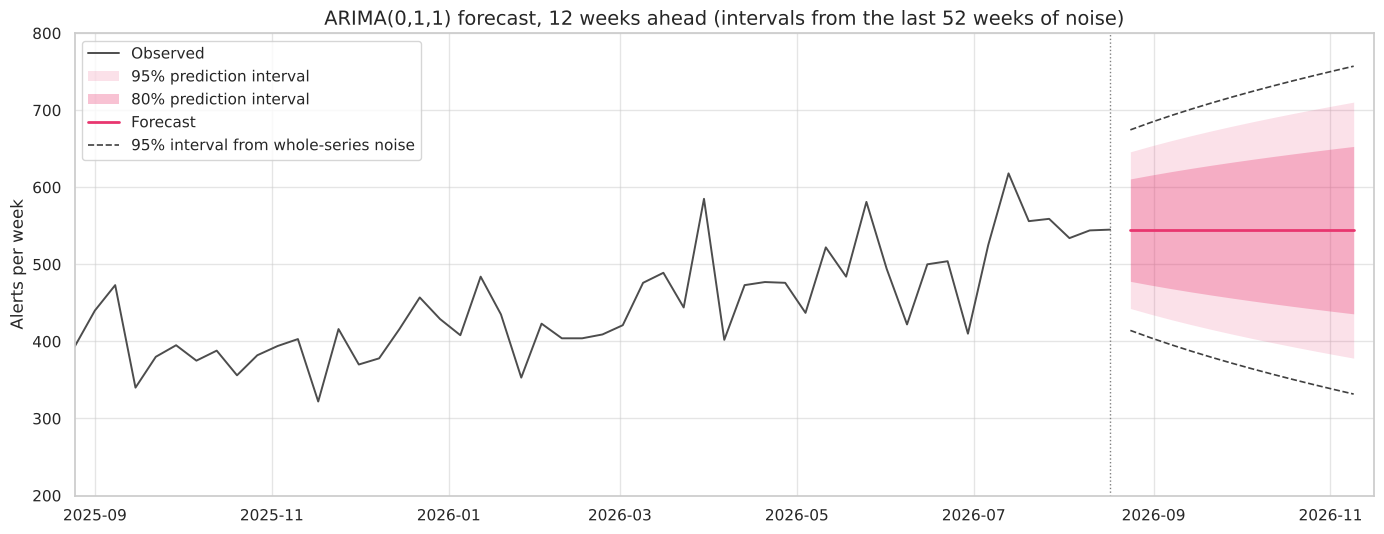

In [26]:
history = weekly.iloc[-52:]  # the last year, for context

fig, ax = plt.subplots(figsize=(14, 5.5))

ax.plot(history.index, history.values, color="0.3", linewidth=1.4, label="Observed")
ax.fill_between(forecast.index, forecast["95% low"], forecast["95% high"],
                color="#e8366f", alpha=0.15, linewidth=0, label="95% prediction interval")
ax.fill_between(forecast.index, forecast["80% low"], forecast["80% high"],
                color="#e8366f", alpha=0.30, linewidth=0, label="80% prediction interval")
ax.plot(forecast.index, forecast["forecast"], color="#e8366f", linewidth=2, label="Forecast")
# the model's own, wider 95% interval, drawn as an outline to show what the rescaling changed
ax.plot(forecast.index, forecast["95% low, whole-series noise"], color="0.25", linewidth=1.2, linestyle="--",
        label="95% interval from whole-series noise")
ax.plot(forecast.index, forecast["95% high, whole-series noise"], color="0.25", linewidth=1.2, linestyle="--")
ax.axvline(weekly.index[-1], color="0.5", linewidth=1, linestyle=":")

ax.set_title(f"ARIMA(0,1,1) forecast, {HORIZON} weeks ahead (intervals from the last {RECENT_WEEKS} weeks of noise)",
             fontsize=14)
ax.set_ylabel("Alerts per week")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlim(history.index.min(), forecast.index.max() + pd.Timedelta(days=7))
ax.set_ylim(200, 800)  # zoomed in on the range of the last year so the two interval widths can be told apart
ax.grid(alpha=0.5)
ax.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()

### How far to trust the forecast

An interval is useful only if it holds on unseen data. At each of the last 104 weeks we forecast 1, 4, 8 and 12 weeks ahead and record the miss, the naive miss, and how often the actual count fell inside the interval, built from whole-series noise and from recent noise.

A well-calibrated 95% interval contains the actual value about 95% of the time; two or three percentage points off is within chance here.

In [27]:
horizons = [1, 4, 8, 12]
levels = {"80%": stats.norm.ppf(0.90), "95%": stats.norm.ppf(0.975)}
records = {h: {"miss": [], "naive miss": [],
               **{f"{name}, {kind}": [] for name in levels for kind in ("whole-series noise", "recent noise")}}
           for h in horizons}

for step in range(RECHECK_WEEKS):
    history = weekly.iloc[:recheck_start + step]
    fit = ARIMA(history, order=(0, 1, 1)).fit()
    prediction = fit.get_forecast(max(horizons))
    means = prediction.predicted_mean.to_numpy()
    errors_whole = prediction.se_mean.to_numpy()
    errors_recent = errors_whole * recent_noise_ratio(fit)
    for h in horizons:
        target = recheck_start + step + h - 1
        if target >= len(weekly):
            continue
        miss = abs(means[h - 1] - weekly.iloc[target])
        records[h]["miss"].append(miss)
        records[h]["naive miss"].append(abs(history.iloc[-1] - weekly.iloc[target]))
        for name, z in levels.items():
            records[h][f"{name}, whole-series noise"].append(miss <= z * errors_whole[h - 1])
            records[h][f"{name}, recent noise"].append(miss <= z * errors_recent[h - 1])

by_horizon = pd.DataFrame({h: {key: np.mean(values) for key, values in records[h].items()} for h in horizons}).T
by_horizon.insert(0, "forecasts tested", [len(records[h]["miss"]) for h in horizons])
by_horizon = by_horizon.rename(columns={"miss": "MAE", "naive miss": "naive MAE"})
by_horizon.insert(3, "MASE", by_horizon["MAE"] / by_horizon["naive MAE"])
by_horizon.index.name = "weeks ahead"

print("Accuracy:")
print(by_horizon[["forecasts tested", "MAE", "naive MAE", "MASE"]].round(2).to_string())
print()
print("Share of actual counts inside the interval (target: 0.80 and 0.95):")
by_horizon[[column for column in by_horizon.columns if "noise" in column]].round(2)

Accuracy:
             forecasts tested    MAE  naive MAE  MASE
weeks ahead                                          
1                         104  36.51      46.67  0.78
4                         101  45.05      53.95  0.84
8                          97  52.41      55.81  0.94
12                         93  61.01      65.85  0.93

Share of actual counts inside the interval (target: 0.80 and 0.95):


,"80%, whole-series noise","80%, recent noise","95%, whole-series noise","95%, recent noise"
weeks ahead,,,,
1,0.90,0.83,0.97,0.93
4,0.95,0.86,0.99,0.97
8,0.97,0.91,1.00,0.99
12,0.97,0.90,1.00,0.98


### A check against the days after the series ends

The weekly series stops on 23 August 2026, but the daily file holds a few complete days after that date. Their daily average, multiplied by seven, gives a rough weekly rate to compare with the forecast.

In [28]:
series_end = weekly.index[-1] + pd.Timedelta(days=6)
later_days = daily.loc[(daily.index > series_end) & ~daily["incomplete_data"], "alerts"]

print(f"{len(later_days)} complete days after {series_end:%d %b %Y}: "
      + ", ".join(f"{day:%d %b}" for day in later_days.index))
print(f"average {later_days.mean():.0f} alerts a day, a weekly rate of about {later_days.mean() * 7:.0f}")
print(f"forecast for those weeks: {forecast['forecast'].iloc[0]:.0f}, "
      f"95% interval {forecast['95% low'].iloc[0]:.0f} to {forecast['95% high'].iloc[1]:.0f}")
print("for comparison, the last 4 weeks of the series averaged "
      f"{weekly.iloc[-4:].mean() / 7:.0f} alerts a day")

9 complete days after 23 Aug 2026: 24 Aug, 25 Aug, 26 Aug, 27 Aug, 28 Aug, 03 Sep, 04 Sep, 05 Sep, 06 Sep
average 101 alerts a day, a weekly rate of about 709
forecast for those weeks: 544, 95% interval 443 to 653
for comparison, the last 4 weeks of the series averaged 78 alerts a day


### Reading the forecast

- **It describes the level, not individual weeks.** It cannot say which weeks will surge.
- **The advantage fades with the horizon.** At 8 to 12 weeks the model and the naive forecast are close.
- **Intervals built on recent noise are narrower and better calibrated** than those built on whole-series noise.
- **The winter dip is left out,** because a yearly term did not improve forecasts.
- **The days after 23 August ran above the 95% interval.** Nine days are thin evidence, but they suggest the level stepped up. A flat forecast cannot anticipate a step; it catches up by a fraction of the error each week.

## 8. Bringing the forecast up to date with eTryvoga data

**The problem.** The official log has a hole in late August and stops on 7 September 2026, so the series ends on 23 August and the section 7 forecast starts in the past.

**The idea.** eTryvoga, a volunteer-run Telegram channel, logs alerts per oblast up to the present. We use it to estimate the missing weeks, test the section 7 forecast against them, and re-forecast.

**Two rules.**

- Sections 1 to 7 and the official datasets stay unchanged; estimates are always labelled as estimates.
- A forecast uses only information published before it is made.

### Step 1. Load the eTryvoga counts and compare them with ours

eTryvoga's daily counts summed into complete weeks (Monday to Sunday), compared with the official series over the period both cover.

In [29]:
etryvoga_daily = pd.read_csv("data/processed/etryvoga_daily_alerts.csv", parse_dates=["date"], index_col="date")


def complete_weeks(daily_frame):
    """Weekly totals (Monday to Sunday) of the weeks in which all seven days are complete."""
    week_start = daily_frame.index - pd.to_timedelta(daily_frame.index.dayofweek, unit="D")
    grouped = daily_frame.groupby(week_start)
    is_full = grouped["incomplete_data"].agg(lambda flags: len(flags) == 7 and not flags.any())
    totals = grouped["alerts"].sum()[is_full]
    totals.index.name = "week_start"
    return totals


etryvoga_weekly = complete_weeks(etryvoga_daily)
print(f"eTryvoga: {len(etryvoga_weekly)} complete weeks, {etryvoga_weekly.index[0]:%d %b %Y} to "
      f"{etryvoga_weekly.index[-1] + pd.Timedelta(days=6):%d %b %Y}")

both = pd.DataFrame({"official": weekly, "eTryvoga": etryvoga_weekly.reindex(weekly.index)})

periods = {
    "2022": ("2022-01-01", "2022-12-31"),
    "2023": ("2023-01-01", "2023-12-31"),
    "2024": ("2024-01-01", "2024-12-31"),
    "2025, Jan-Jul": ("2025-01-01", "2025-07-31"),
    "2025, Aug-Dec": ("2025-08-01", "2025-12-31"),
    "2026": ("2026-01-01", "2026-12-31"),
}
comparison_by_period = pd.DataFrame({
    name: {
        "weeks": len(both.loc[start:end]),
        "official, mean": both.loc[start:end, "official"].mean(),
        "eTryvoga, mean": both.loc[start:end, "eTryvoga"].mean(),
        "ratio": both.loc[start:end, "eTryvoga"].mean() / both.loc[start:end, "official"].mean(),
        "correlation": both.loc[start:end, "official"].corr(both.loc[start:end, "eTryvoga"]),
    }
    for name, (start, end) in periods.items()
}).T
comparison_by_period.round(2)

eTryvoga: 240 complete weeks, 28 Feb 2022 to 04 Oct 2026


,weeks,"official, mean","eTryvoga, mean",ratio,correlation
2022,41.0,362.10,336.88,0.93,0.98
2023,52.0,329.38,365.44,1.11,0.99
2024,53.0,477.92,485.21,1.02,0.95
"2025, Jan-Jul",30.0,419.60,428.57,1.02,0.96
"2025, Aug-Dec",22.0,406.95,532.00,1.31,0.15
2026,33.0,478.73,731.36,1.53,0.84


- **Until mid-2025** the two sources agree closely.
- **From August 2025,** when alerts began to be declared per raion instead of per oblast, eTryvoga counts markedly more alerts, because the two sources turn raion-level alerts into oblast-level counts differently.
- **In 2026** the relationship is steady again, at a new ratio.

So eTryvoga cannot replace the official series, but within 2026 it can be converted to our scale.

### Step 2. Fit the conversion

A straight line from eTryvoga's weekly count to ours, fitted on the weeks of 2026 that both sources cover. The spread of the points around the line is the **conversion error**: how far a converted week typically is from the official count.

fitted on 33 weeks: official = 19.9 + 0.627 x eTryvoga
correlation 0.84; conversion error (standard deviation) 35 alerts per week


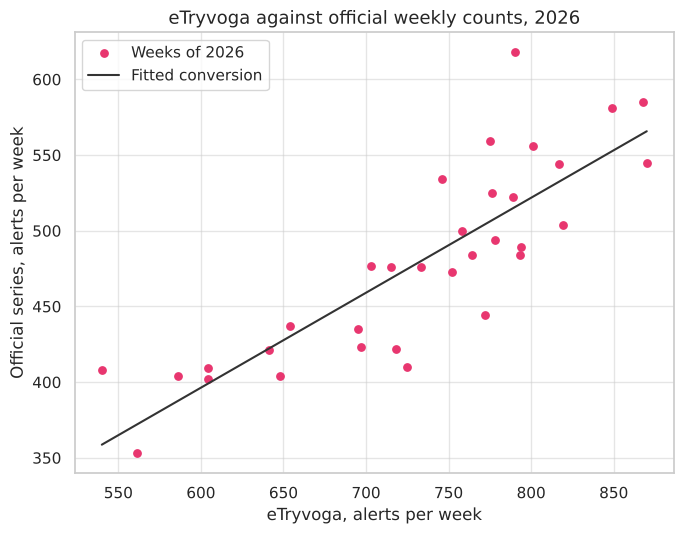

In [30]:
CONVERSION_START = "2026-01-01"

overlap = both.loc[CONVERSION_START:].dropna()
slope, intercept = np.polyfit(overlap["eTryvoga"], overlap["official"], 1)
fitted_line = intercept + slope * overlap["eTryvoga"]
conversion_error = np.sqrt(((overlap["official"] - fitted_line) ** 2).sum() / (len(overlap) - 2))


def to_official_scale(etryvoga_count):
    return intercept + slope * etryvoga_count


print(f"fitted on {len(overlap)} weeks: official = {intercept:.1f} + {slope:.3f} x eTryvoga")
print(f"correlation {overlap['official'].corr(overlap['eTryvoga']):.2f}; "
      f"conversion error (standard deviation) {conversion_error:.0f} alerts per week")

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(overlap["eTryvoga"], overlap["official"], color="#e8366f", s=28, label="Weeks of 2026")
line_x = np.array([overlap["eTryvoga"].min(), overlap["eTryvoga"].max()])
ax.plot(line_x, to_official_scale(line_x), color="0.2", linewidth=1.5, label="Fitted conversion")
ax.set_title("eTryvoga against official weekly counts, 2026", fontsize=13)
ax.set_xlabel("eTryvoga, alerts per week")
ax.set_ylabel("Official series, alerts per week")
ax.grid(alpha=0.5)
ax.legend(loc="upper left", frameon=True)
plt.tight_layout()
plt.show()

### Step 3. Check the conversion on official data

One check outside the fitting period: the few complete official days after 23 August (section 7). We convert eTryvoga's counts for those days and compare them with the official log.

In [31]:
etryvoga_same_days = etryvoga_daily.loc[later_days.index, "alerts"]

official_rate = later_days.mean() * 7
converted_rate = to_official_scale(etryvoga_same_days.mean() * 7)

print(f"{len(later_days)} complete official days after {series_end:%d %b %Y}")
print(f"official log, weekly rate:          {official_rate:.0f}")
print(f"eTryvoga converted, weekly rate:    {converted_rate:.0f}")
print(f"the conversion is {abs(converted_rate / official_rate - 1):.0%} "
      f"{'below' if converted_rate < official_rate else 'above'} the official figure on these days")

9 complete official days after 23 Aug 2026
official log, weekly rate:          709
eTryvoga converted, weekly rate:    660
the conversion is 7% below the official figure on these days


### Step 4. Estimate the missing weeks

Every complete eTryvoga week after the official series ends, converted to our scale. Each estimate is uncertain by about the conversion error. The estimates are listed in step 5.

In [32]:
new_weeks = etryvoga_weekly[etryvoga_weekly.index > weekly.index[-1]]

estimated = pd.DataFrame({
    "eTryvoga count": new_weeks,
    "estimate, official scale": to_official_scale(new_weeks).round(0),
})
estimated["plus or minus (95%)"] = round(1.96 * conversion_error)

print(f"{len(estimated)} estimated weeks, {estimated.index[0]:%d %b %Y} to "
      f"{estimated.index[-1] + pd.Timedelta(days=6):%d %b %Y}")
print(f"for comparison, the last 4 official weeks averaged {weekly.iloc[-4:].mean():.0f}")

6 estimated weeks, 24 Aug 2026 to 04 Oct 2026
for comparison, the last 4 official weeks averaged 546


### Step 5. Test the section 7 forecast against the estimates

The section 7 forecast used data up to 23 August, so the model never saw the estimated weeks. This is a true out-of-sample test, with the caveat that the "actual" values are themselves estimates.

In [33]:
forecast_test = forecast.loc[estimated.index, ["forecast", "95% low", "95% high"]].round(0)
forecast_test["estimated actual"] = estimated["estimate, official scale"]
forecast_test["miss"] = forecast_test["estimated actual"] - forecast_test["forecast"]
forecast_test["against the 95% interval"] = np.select(
    [forecast_test["estimated actual"] > forecast_test["95% high"],
     forecast_test["estimated actual"] < forecast_test["95% low"]],
    ["above", "below"], default="inside")

n_outside = int((forecast_test["against the 95% interval"] != "inside").sum())
print(f"{n_outside} of {len(forecast_test)} weeks fall outside the 95% interval; "
      f"all misses have the same sign: {bool((forecast_test['miss'] > 0).all() or (forecast_test['miss'] < 0).all())}")
print(f"average miss: {forecast_test['miss'].mean():+.0f} alerts per week "
      f"({forecast_test['miss'].mean() / forecast_test['forecast'].mean():+.0%})")
forecast_test.astype({column: int for column in ["forecast", "95% low", "95% high", "estimated actual", "miss"]})

3 of 6 weeks fall outside the 95% interval; all misses have the same sign: True
average miss: +129 alerts per week (+24%)


,forecast,95% low,95% high,estimated actual,miss,against the 95% interval
week_start,,,,,,
2026-08-24,544,443,646,697,153,above
2026-08-31,544,435,653,695,151,above
2026-09-07,544,428,660,601,57,inside
2026-09-14,544,422,667,650,106,inside
2026-09-21,544,415,673,745,201,above
2026-09-28,544,410,679,650,106,inside


### Step 6. Re-forecast from the latest complete week

ARIMA(0,1,1) fitted on the official weeks followed by the estimated weeks. The interval is built as in section 7 and then widened for the conversion error, which carries into the forecast in proportion to the weights the model gives to recent weeks.

In [34]:
extended = pd.concat([weekly, estimated["estimate, official scale"]]).asfreq("W-MON")
assert extended.notna().all()

updated_fit = ARIMA(extended, order=(0, 1, 1)).fit()
updated_correction = 1 + updated_fit.params["ma.L1"]
updated_ratio = recent_noise_ratio(updated_fit)

# share of the conversion error that reaches the forecast through the fading weights
level_error = conversion_error * np.sqrt(updated_correction / (2 - updated_correction))

updated_prediction = updated_fit.get_forecast(HORIZON)
updated_error = np.sqrt((updated_prediction.se_mean * updated_ratio) ** 2 + level_error ** 2)

updated_forecast = pd.DataFrame({"forecast": updated_prediction.predicted_mean})
for level in (0.80, 0.95):
    z = stats.norm.ppf(0.5 + level / 2)
    updated_forecast[f"{level:.0%} low"] = updated_forecast["forecast"] - z * updated_error
    updated_forecast[f"{level:.0%} high"] = updated_forecast["forecast"] + z * updated_error
updated_forecast.index.name = "week_start"

print(f"fitted on {len(weekly)} official + {len(estimated)} estimated weeks, "
      f"to {extended.index[-1] + pd.Timedelta(days=6):%d %b %Y}")
print(f"correction fraction {updated_correction:.0%} (section 7: {correction:.0%})")
print(f"noise over the last {RECENT_WEEKS} weeks: {updated_ratio * np.sqrt(updated_fit.params['sigma2']):.0f} "
      f"alerts per week (section 7: {ratio * model_sigma:.0f}); added for conversion error: {level_error:.0f}")
print(f"forecast level: {updated_forecast['forecast'].iloc[0]:.0f} alerts per week "
      f"(section 7: {forecast['forecast'].iloc[0]:.0f})")
updated_forecast.round(0).astype(int).iloc[[0, 1, 3, 7, 11]]  # weeks 1, 2, 4, 8 and 12

fitted on 231 official + 6 estimated weeks, to 04 Oct 2026
correction fraction 40% (section 7: 39%)
noise over the last 52 weeks: 56 alerts per week (section 7: 52); added for conversion error: 18
forecast level: 668 alerts per week (section 7: 544)


,forecast,80% low,80% high,95% low,95% high
week_start,,,,,
2026-10-05,668,592,743,552,783
2026-10-12,668,587,748,544,791
2026-10-26,668,577,758,529,806
2026-11-23,668,560,775,503,832
2026-12-21,668,546,789,481,854


### Step 7. Both forecasts in one chart

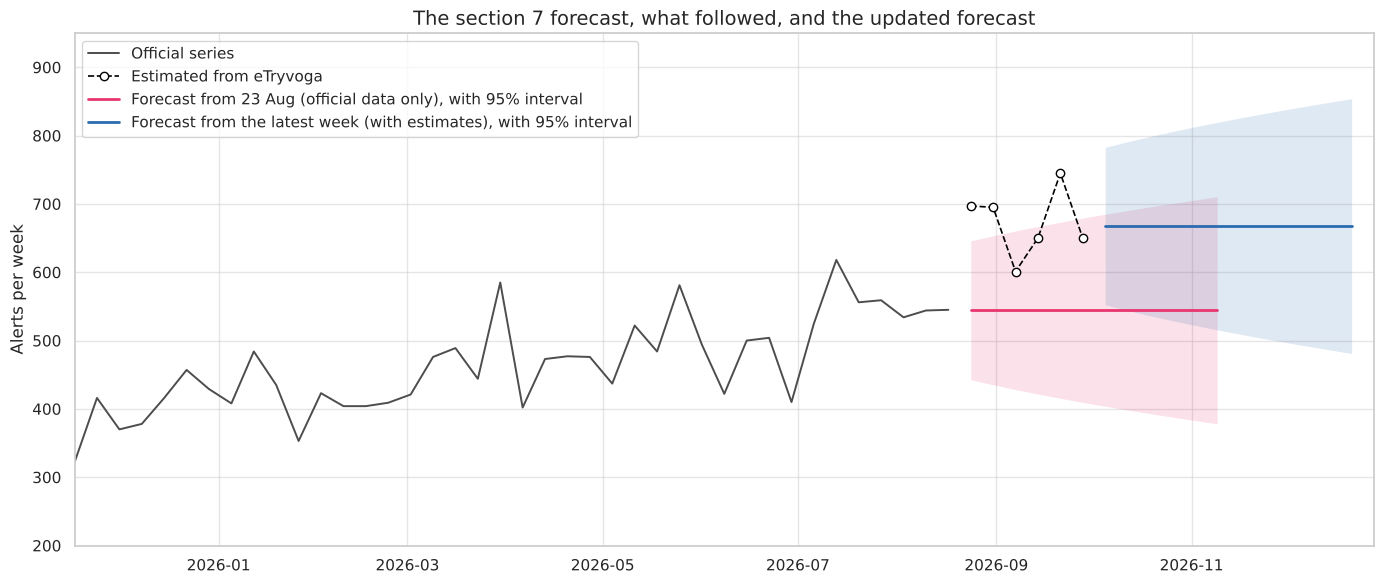

In [35]:
recent = weekly.iloc[-40:]

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(recent.index, recent.values, color="0.3", linewidth=1.4, label="Official series")
ax.plot(estimated.index, estimated["estimate, official scale"], color="black", linewidth=1.2, linestyle="--",
        marker="o", markersize=6, markerfacecolor="white", label="Estimated from eTryvoga")

for frame, color, label in [(forecast, "#e8366f", "Forecast from 23 Aug (official data only)"),
                            (updated_forecast, "#2b6cb0", "Forecast from the latest week (with estimates)")]:
    ax.fill_between(frame.index, frame["95% low"], frame["95% high"], color=color, alpha=0.15, linewidth=0)
    ax.plot(frame.index, frame["forecast"], color=color, linewidth=2, label=f"{label}, with 95% interval")

ax.set_title("The section 7 forecast, what followed, and the updated forecast", fontsize=14)
ax.set_ylabel("Alerts per week")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlim(recent.index.min(), updated_forecast.index.max() + pd.Timedelta(days=7))
ax.set_ylim(200, 950)
ax.grid(alpha=0.5)
ax.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()

### What this section shows

- **The level stepped up at the end of August.** Every estimated week is above the section 7 forecast, and several are above its 95% interval.
- **This is a level shift,** which no model in section 6 can predict from past counts.
- **The updated forecast starts from the new level,** with wider intervals because the conversion error is added.

### Limits of this section

- **The estimates are not official counts,** and are more likely too low than too high (step 3).
- **The conversion can break** if eTryvoga changes how it counts, as happened in 2025.

## 9. Time under alert: a second view of the same log

**Why we come back to the decomposition.** Section 3 left a question open: the trend of the count is nearly flat, although the threat is reported to have grown. A count can stay flat while alerts get longer. We test this by measuring time and repeating the steps of sections 3 to 7.

**The measure.** `alert_hours` is the hours a district (raion) spent under alert in a week, averaged over all districts. A district is under alert while an alert is in force for it or for its whole oblast. The maximum is 168, a full week.

**A related split.** `regional_alerts` and `local_alerts` (alerts for a single hromada) divide the count. Published statistics count regional alerts only.

### Step 1. The series, and how it compares with the count

In [36]:
hours = weekly_file.loc[weekly.index, "alert_hours"].asfreq("W-MON")
assert hours.notna().all()

per_year = weekly_file.loc[weekly.index].groupby(weekly.index.year).agg(
    weeks=("alerts", "size"),
    alerts=("alerts", "mean"),
    regional_alerts=("regional_alerts", "mean"),
    local_alerts=("local_alerts", "mean"),
    alert_hours=("alert_hours", "mean"),
)
per_year["share of time under alert"] = per_year["alert_hours"] / 168
per_year.index.name = "year (weekly averages)"

first_year, last_year = per_year.index[1], per_year.index[-1]  # first full year and the latest
print(f"{first_year} to {last_year}: alerts per week x{per_year.loc[last_year, 'alerts'] / per_year.loc[first_year, 'alerts']:.2f}, "
      f"hours under alert x{per_year.loc[last_year, 'alert_hours'] / per_year.loc[first_year, 'alert_hours']:.2f}")
per_year.round(2)

2023 to 2026: alerts per week x1.45, hours under alert x2.53


,weeks,alerts,regional_alerts,local_alerts,alert_hours,share of time under alert
year (weekly averages),,,,,,
2022,41,362.10,334.56,27.54,13.80,0.08
2023,52,329.38,311.77,17.62,14.85,0.09
2024,53,477.92,415.02,62.91,27.31,0.16
2025,52,414.25,367.46,46.79,33.32,0.20
2026,33,478.73,468.48,10.24,37.56,0.22


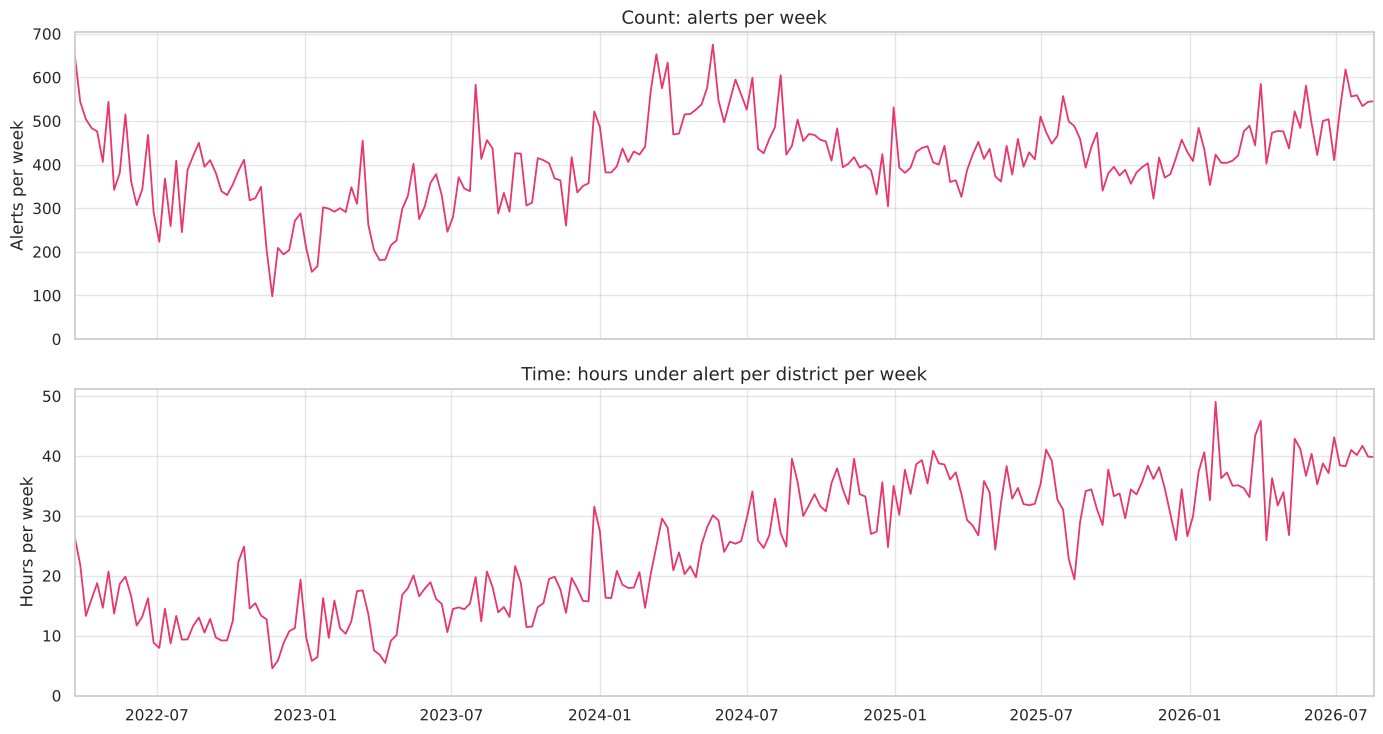

In [37]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7.5), sharex=True)

for ax, series, title, ylabel in [(axes[0], weekly, "Count: alerts per week", "Alerts per week"),
                                  (axes[1], hours, "Time: hours under alert per district per week", "Hours per week")]:
    sns.lineplot(x=series.index, y=series.values, color="#e8366f", linewidth=1.3, ax=ax)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
    ax.set_ylim(0, None)
    ax.grid(alpha=0.5)
axes[1].set_xlim(weekly.index.min(), weekly.index.max())

plt.tight_layout()
plt.show()

### Step 2. Decomposition

The same STL settings as in section 3, so the two decompositions can be compared directly.

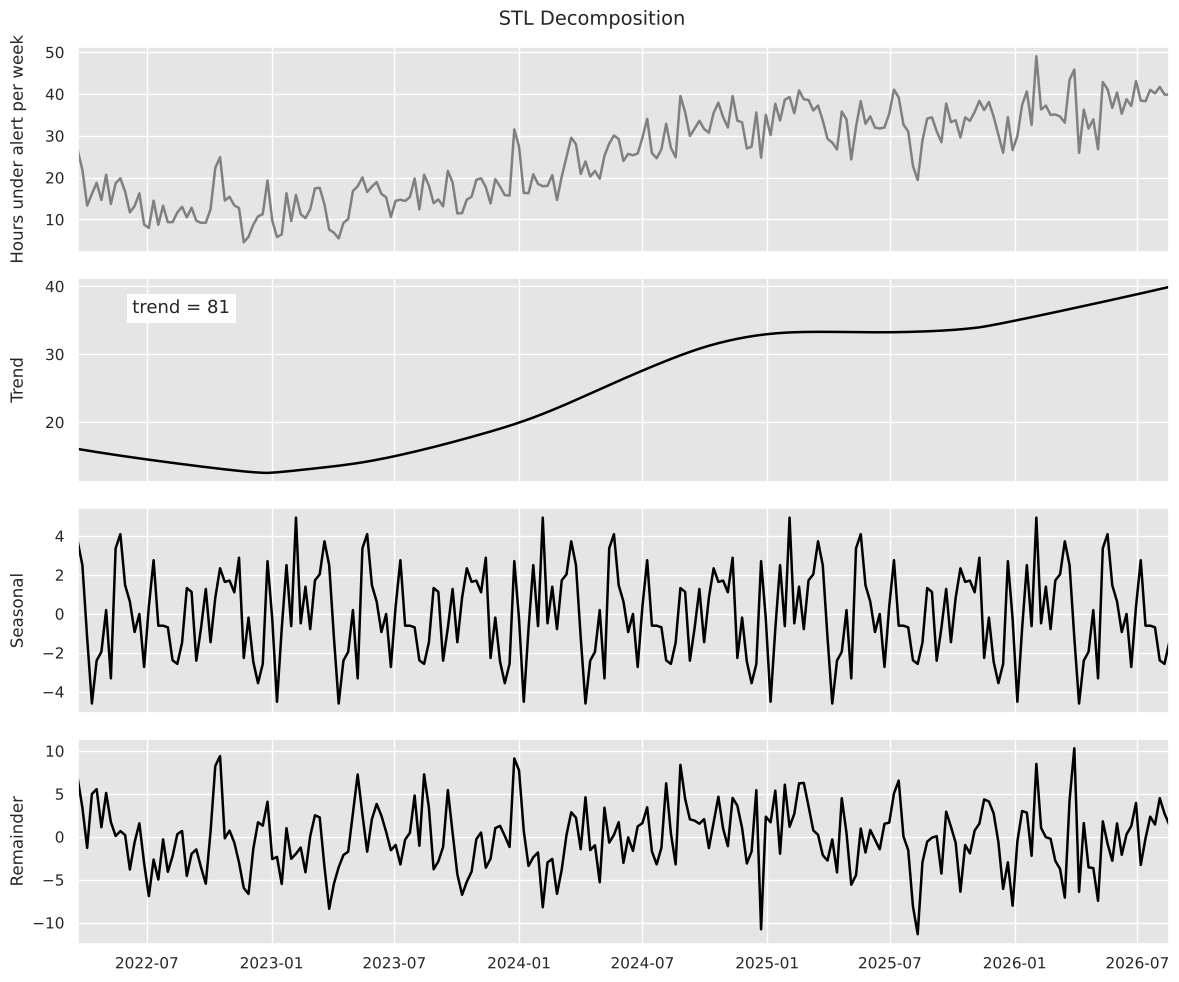

In [38]:
hours_stl = STL(hours, period=PERIOD, seasonal=SEASONAL_WINDOW, seasonal_deg=0,
                trend=TREND_WINDOW, robust=False).fit()

hours_parts = pd.DataFrame({
    "original": hours,
    "trend": hours_stl.trend,
    "seasonal": hours_stl.seasonal,
    "remainder": hours_stl.resid,
})
assert np.allclose(hours_parts["original"], hours_parts[["trend", "seasonal", "remainder"]].sum(axis=1))

plot_stl(hours_parts, TREND_WINDOW, "Hours under alert per week")

In [39]:
def decomposition_summary(frame):
    return pd.Series({
        "trend strength": strength(frame["trend"], frame["remainder"]),
        "seasonal strength": strength(frame["seasonal"], frame["remainder"]),
        "trend, share of variance": frame["trend"].var() / frame["original"].var(),
        "seasonal, share of variance": frame["seasonal"].var() / frame["original"].var(),
        "remainder, share of variance": frame["remainder"].var() / frame["original"].var(),
        "lag-1 autocorrelation of the series": frame["original"].autocorr(1),
    })


pd.DataFrame({
    "count of alerts": decomposition_summary(parts),
    "hours under alert": decomposition_summary(hours_parts),
}).round(2)

,count of alerts,hours under alert
trend strength,0.59,0.87
seasonal strength,0.34,0.26
"trend, share of variance",0.33,0.78
"seasonal, share of variance",0.17,0.05
"remainder, share of variance",0.33,0.13
lag-1 autocorrelation of the series,0.71,0.88


**This answers the question from section 3.** Measured in hours, the trend climbs where the count stayed in a band. The trend is the dominant component, and the remainder is a much smaller share of the variance. The threat grew through longer and wider alerts, which a count cannot register.

Steps 3 and 4 repeat sections 4 and 5, so that the choice of model is argued in the same way as for the count.

### Step 3. Autocorrelation of the remainder

The same check as in section 4: if trend and season captured everything, all bars would fall inside the band.

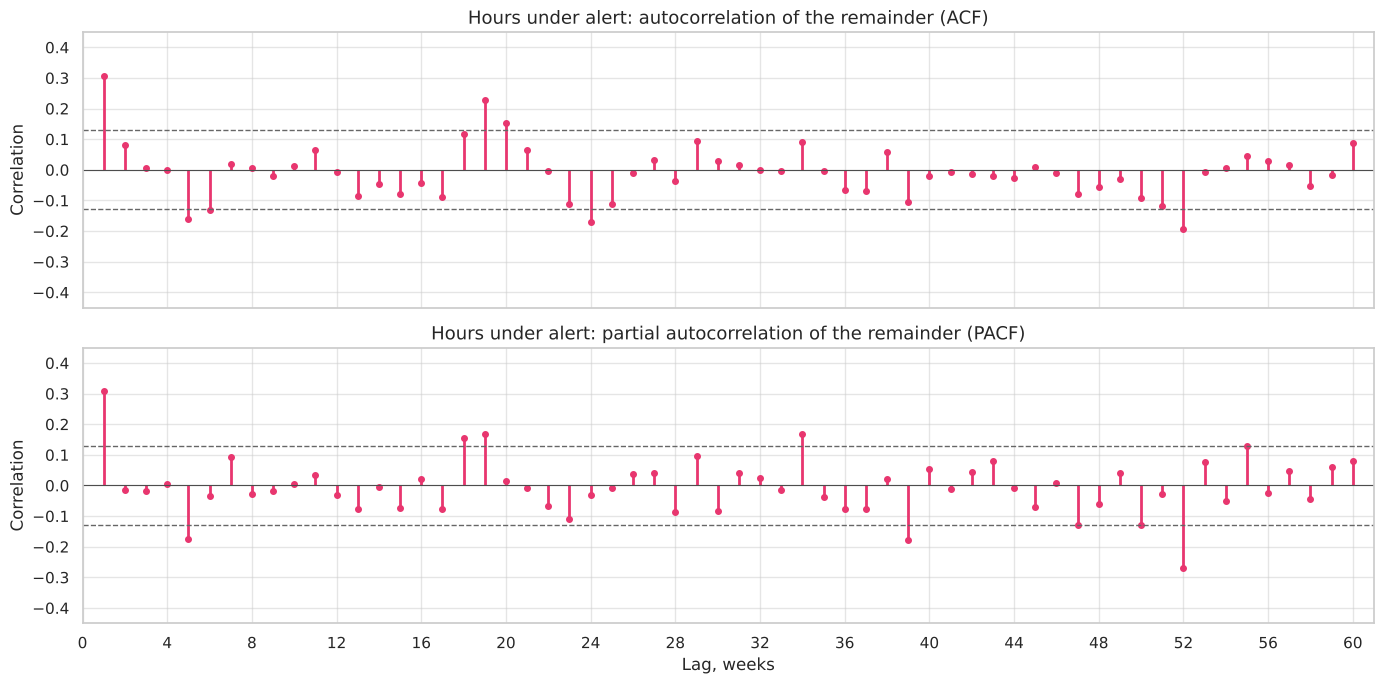

white-noise band: +/-0.129
ACF at lags 1-4: [ 0.31  0.08  0.01 -0.  ]   (count, section 4: [0.34 0.23 0.14 0.11])
lags with ACF outside the band: [1, 5, 6, 19, 20, 24, 52]


In [40]:
hours_remainder = hours_parts["remainder"]
hours_band = 1.96 / np.sqrt(len(hours_remainder))

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
hours_remainder_acf = plot_correlogram(hours_remainder, "acf",
                                       "Hours under alert: autocorrelation of the remainder (ACF)", axes[0])
plot_correlogram(hours_remainder, "pacf",
                 "Hours under alert: partial autocorrelation of the remainder (PACF)", axes[1])
for ax in axes:
    ax.set_ylim(-0.45, 0.45)
axes[1].set_xlabel("Lag, weeks")

plt.tight_layout()
plt.show()

hours_outside = [k for k in range(1, MAX_LAG + 1) if abs(hours_remainder_acf[k]) > hours_band]
print(f"white-noise band: +/-{hours_band:.3f}")
print(f"ACF at lags 1-4: {hours_remainder_acf[1:5].round(2)}   (count, section 4: {acf_values[1:5].round(2)})")
print(f"lags with ACF outside the band: {hours_outside}")

In [41]:
# Ljung-Box test on the remainder, and on what an AR(1) model of the remainder leaves behind (as in section 4).
hours_ar1 = ARIMA(hours_remainder, order=(1, 0, 0), trend="n").fit()

print(f"AR(1) coefficient: {hours_ar1.params['ar.L1']:.2f}   (count, section 4: {ar1.params['ar.L1']:.2f})")
print(f"share of the remainder's variance explained by last week's value: "
      f"{1 - hours_ar1.resid.var() / hours_remainder.var():.0%}")

hours_remainder_tests = pd.DataFrame({
    "remainder": acorr_ljungbox(hours_remainder, lags=[4, 8, 13, 26])["lb_pvalue"],
    "remainder after AR(1)": acorr_ljungbox(hours_ar1.resid, lags=[4, 8, 13, 26], model_df=1)["lb_pvalue"],
})
hours_remainder_tests.index.name = "Ljung-Box p-value, up to lag (weeks)"
hours_remainder_tests.round(3)

AR(1) coefficient: 0.31   (count, section 4: 0.35)
share of the remainder's variance explained by last week's value: 9%


,remainder,remainder after AR(1)
"Ljung-Box p-value, up to lag (weeks)",,
4,0.0,0.859
8,0.0,0.199
13,0.0,0.348
26,0.0,0.039


**Reading.** The remainder is not white noise, as for the count. Its memory is shorter: only last week's value matters, and an AR(1) term removes nearly all of it.

**Carried forward:** the model needs a short-memory term, and is worth testing with one term more.

### Step 4. Stationarity and autocorrelation of the series

The same tests and charts as in section 5.

In [42]:
hours_diff = hours.diff().dropna()

hours_stationarity = pd.DataFrame({
    "series, around a constant": stationarity_tests(hours, "c"),
    "series, around a linear trend": stationarity_tests(hours, "ct"),
    "first difference": stationarity_tests(hours_diff, "c"),
}).T
hours_stationarity[hours_stationarity.columns[:4]] = hours_stationarity[hours_stationarity.columns[:4]].astype(float).round(3)

print("verdicts for the count (section 5): " + "; ".join(f"{name}: {verdict}" for name, verdict in stationarity["verdict"].items()))
hours_stationarity

verdicts for the count (section 5): series, around a constant: tests disagree; series, around a linear trend: stationary; first difference: stationary


,ADF statistic,ADF p-value,KPSS statistic,KPSS p-value,verdict
"series, around a constant",-0.305,0.925,2.197,0.01,not stationary
"series, around a linear trend",-3.798,0.017,0.223,0.01,tests disagree
first difference,-8.190,0.000,0.238,0.10,stationary


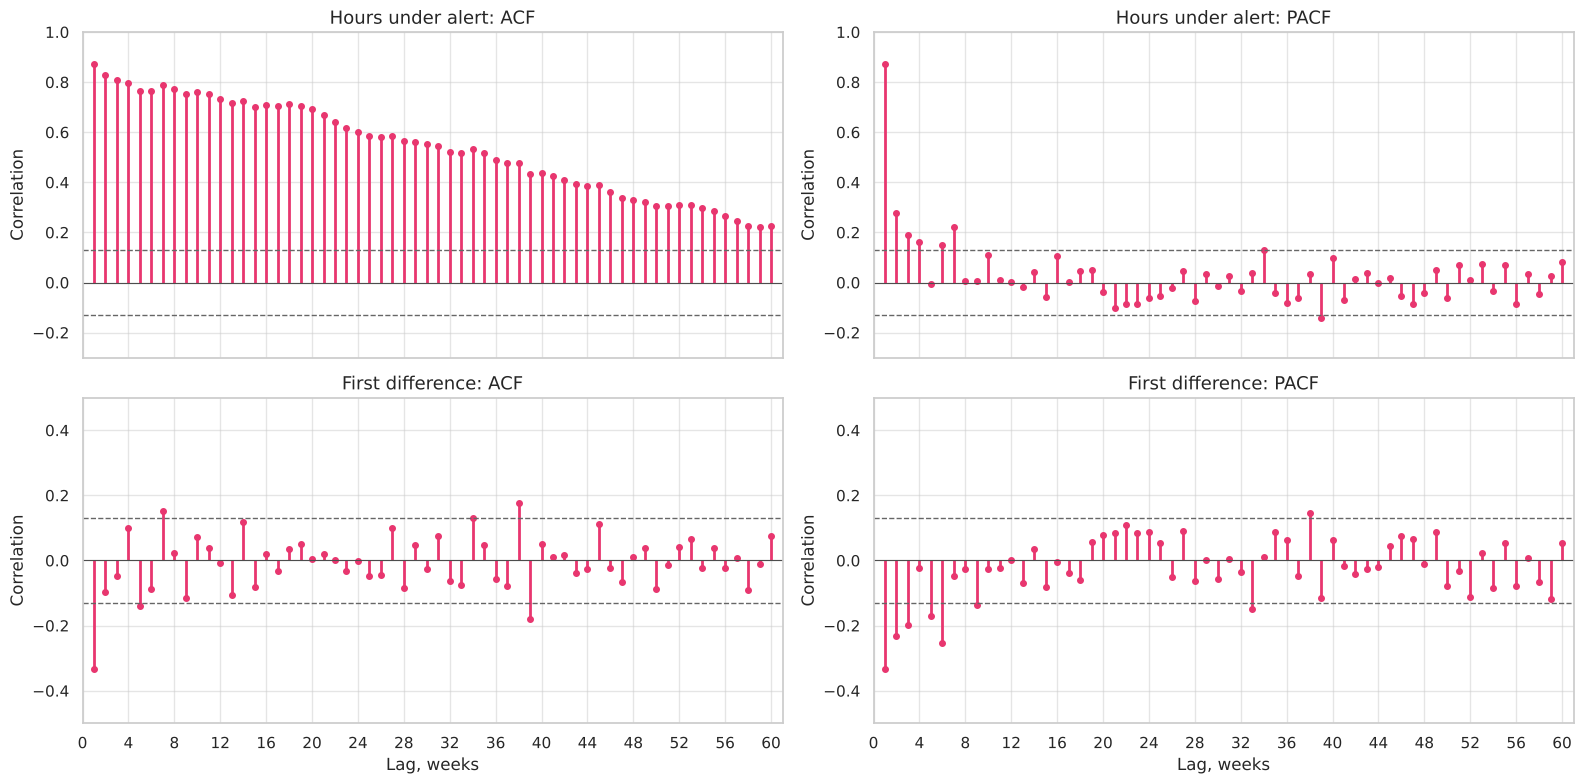

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True)

hours_level_acf = plot_correlogram(hours, "acf", "Hours under alert: ACF", axes[0, 0])
hours_level_pacf = plot_correlogram(hours, "pacf", "Hours under alert: PACF", axes[0, 1])
hours_diff_acf = plot_correlogram(hours_diff, "acf", "First difference: ACF", axes[1, 0])
hours_diff_pacf = plot_correlogram(hours_diff, "pacf", "First difference: PACF", axes[1, 1])

for ax in axes[0]:
    ax.set_ylim(-0.3, 1.0)
for ax in axes[1]:
    ax.set_ylim(-0.5, 0.5)
    ax.set_xlabel("Lag, weeks")

plt.tight_layout()
plt.show()

### What we carry into modelling

1. **One difference, more clearly than for the count.** Before differencing, both tests say non-stationary.
2. **The slow decay of the ACF is the trend,** not a long memory: it disappears after differencing.
3. **The difference again looks like a moving average of order 1,** but with a few more bars outside the band. So ARIMA(1,1,1) and ARIMA(0,1,2) are tested alongside ARIMA(0,1,1).
4. **A drift is worth testing,** because the trend is strong.
5. **No seasonal terms:** there is no spike at 52 weeks.

### Step 5. Which model forecasts the hours best?

The walk-forward test of section 6: 104 weeks, one week ahead, every model refitted each week. The candidates are those from step 4, the baselines, and the seasonal models tested on the count. The last column is the paired test against ARIMA(0,1,1), the winner for the count.

In [44]:
hours_models = {
    "Naive": recheck_models["Naive"],
    "Mean of last 4 weeks": recheck_models["Mean of last 4 weeks"],
    "ARIMA(0,1,1)": arima_forecaster((0, 1, 1)),
    "ARIMA(1,1,1)": arima_forecaster((1, 1, 1)),
    "ARIMA(0,1,2)": arima_forecaster((0, 1, 2)),
    "ARIMA(1,1,1) + drift": arima_forecaster((1, 1, 1), trend="t"),
    "ARIMA(1,1,1) + yearly wave": arima_forecaster((1, 1, 1), wave=True),
    "Trend + yearly wave + AR(1)": arima_forecaster((1, 0, 0), trend="ct", wave=True),
    "Holt-Winters, 52-week season": recheck_models["Holt-Winters, 52-week season"],
}

hours_actual = hours.iloc[recheck_start:]
hours_forecasts = pd.DataFrame(index=hours_actual.index, columns=list(hours_models), dtype=float)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # optimiser notices from about 900 fits
    for step in range(RECHECK_WEEKS):
        history = hours.iloc[:recheck_start + step]
        next_index = hours.index[recheck_start + step:recheck_start + step + 1]
        for name, forecast_function in hours_models.items():
            hours_forecasts.loc[next_index[0], name] = forecast_function(history, next_index)

hours_errors = hours_forecasts.sub(hours_actual, axis=0).abs()
hours_scores = pd.DataFrame({
    "MAE": hours_errors.mean(),
    "RMSE": np.sqrt((hours_errors ** 2).mean()),
})
hours_scores["MASE"] = hours_scores["MAE"] / hours_scores.loc["Naive", "MAE"]
hours_scores["p-value vs ARIMA(0,1,1)"] = [
    stats.ttest_1samp(hours_errors[name] - hours_errors["ARIMA(0,1,1)"], 0).pvalue
    if name != "ARIMA(0,1,1)" else np.nan for name in hours_scores.index
]
hours_scores = hours_scores.sort_values("MAE")

print(f"average level over the test weeks: {hours_actual.mean():.1f} hours per week")
hours_scores.round(3)

average level over the test weeks: 34.6 hours per week


,MAE,RMSE,MASE,"p-value vs ARIMA(0,1,1)"
"ARIMA(1,1,1) + drift",3.785,4.941,0.843,0.470
"ARIMA(1,1,1)",3.786,4.970,0.843,0.456
"ARIMA(1,1,1) + yearly wave",3.810,5.007,0.848,0.597
"ARIMA(0,1,2)",3.815,5.003,0.850,0.683
"ARIMA(0,1,1)",3.866,5.041,0.861,NaN
Mean of last 4 weeks,3.993,5.153,0.889,0.223
Trend + yearly wave + AR(1),4.010,5.249,0.893,0.479
Naive,4.490,5.895,1.000,0.024
"Holt-Winters, 52-week season",4.598,5.809,1.024,0.005


**Reading.**

- **The ARIMA variants tie,** as they did for the count. The models with one term more than ARIMA(0,1,1) come out ahead, but by too little for the paired test to confirm.
- **A drift adds nothing:** the rise is not steady enough to forecast with.
- **Seasonality adds nothing:** a yearly wave changes little, and the full 52-week pattern is worse than the naive forecast.

The walk-forward test cannot separate ARIMA(0,1,1) from ARIMA(1,1,1). The residual check in step 6 does.

### Step 6. Do the residuals pass?

The Ljung-Box test for ARIMA(0,1,1) and for ARIMA(1,1,1), which adds a carry-over of last week's change. A p-value below 0.05 means the errors are still autocorrelated, so the model is missing structure.

In [45]:
rows = {}
hours_fits = {}
for order in [(0, 1, 1), (1, 1, 1)]:
    name = f"ARIMA{order}".replace(" ", "")
    fit = ARIMA(hours, order=order).fit()
    hours_fits[name] = fit
    residuals = fit.resid.iloc[1:]
    test = acorr_ljungbox(residuals, lags=[4, 8, 13, 26], model_df=sum(order) - 1)
    rows[name] = {
        "AIC": fit.aic,
        **{f"p-value, up to lag {lag}": p for lag, p in test["lb_pvalue"].items()},
        "share of variance explained, 1 week ahead": 1 - residuals.var() / hours.var(),
    }
    print(f"{name}: " + ", ".join(f"{key} = {value:.2f}" for key, value in fit.params.drop("sigma2").items()))

pd.DataFrame(rows).T.round(3)

ARIMA(0,1,1): ma.L1 = -0.71
ARIMA(1,1,1): ar.L1 = 0.30, ma.L1 = -0.86


,AIC,"p-value, up to lag 4","p-value, up to lag 8","p-value, up to lag 13","p-value, up to lag 26","share of variance explained, 1 week ahead"
"ARIMA(0,1,1)",1363.387,0.017,0.000,0.002,0.001,0.806
"ARIMA(1,1,1)",1352.000,0.746,0.095,0.188,0.141,0.818


### Step 7. Forecast of time under alert

ARIMA(1,1,1) passes the residual test and ARIMA(0,1,1) does not, so we forecast with ARIMA(1,1,1): 12 weeks ahead, with intervals from the noise of the last 52 weeks as in section 7.

Unlike the count forecast, this one is not exactly flat: the carry-over term lets the first weeks drift a little before the forecast settles.

noise over the last 52 weeks: 112% of the whole-series figure


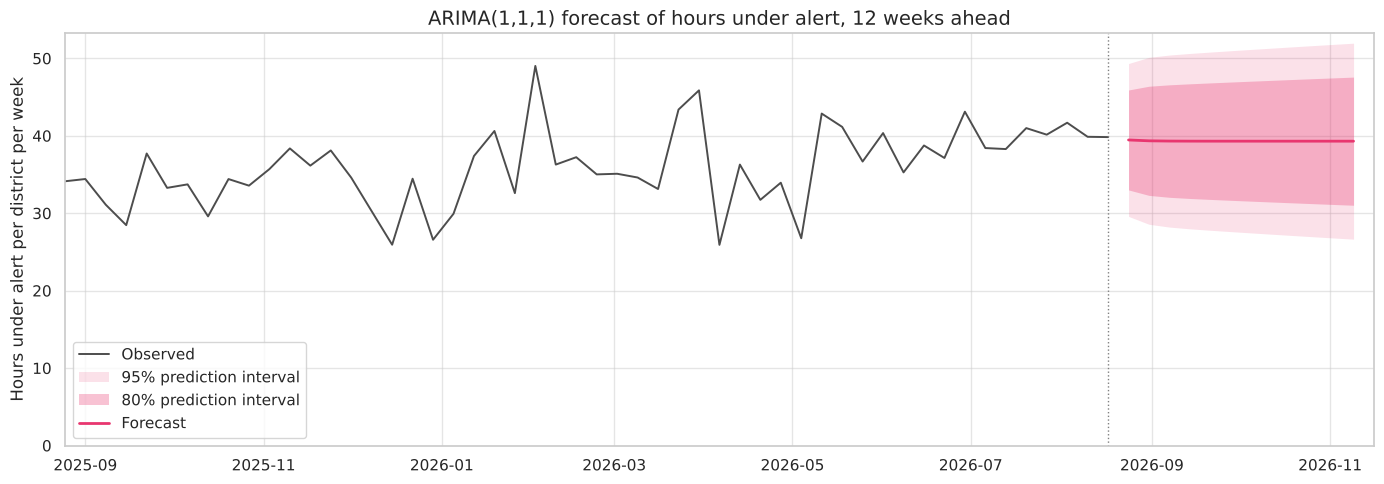

,forecast,80% low,80% high,95% low,95% high
week_start,,,,,
2026-08-24,39.5,33.0,45.9,29.6,49.3
2026-08-31,39.4,32.3,46.4,28.6,50.1
2026-09-14,39.3,31.9,46.7,28.0,50.6
2026-10-12,39.3,31.4,47.2,27.3,51.3
2026-11-09,39.3,31.0,47.6,26.7,52.0


In [46]:
hours_fit = hours_fits["ARIMA(1,1,1)"]
hours_ratio = recent_noise_ratio(hours_fit)
hours_prediction = hours_fit.get_forecast(HORIZON)
hours_standard_error = hours_prediction.se_mean * hours_ratio

hours_forecast = pd.DataFrame({"forecast": hours_prediction.predicted_mean})
for level in (0.80, 0.95):
    z = stats.norm.ppf(0.5 + level / 2)
    hours_forecast[f"{level:.0%} low"] = hours_forecast["forecast"] - z * hours_standard_error
    hours_forecast[f"{level:.0%} high"] = hours_forecast["forecast"] + z * hours_standard_error
hours_forecast.index.name = "week_start"

print(f"noise over the last {RECENT_WEEKS} weeks: {hours_ratio:.0%} of the whole-series figure")

history = hours.iloc[-52:]
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(history.index, history.values, color="0.3", linewidth=1.4, label="Observed")
ax.fill_between(hours_forecast.index, hours_forecast["95% low"], hours_forecast["95% high"],
                color="#e8366f", alpha=0.15, linewidth=0, label="95% prediction interval")
ax.fill_between(hours_forecast.index, hours_forecast["80% low"], hours_forecast["80% high"],
                color="#e8366f", alpha=0.30, linewidth=0, label="80% prediction interval")
ax.plot(hours_forecast.index, hours_forecast["forecast"], color="#e8366f", linewidth=2, label="Forecast")
ax.axvline(hours.index[-1], color="0.5", linewidth=1, linestyle=":")
ax.set_title(f"ARIMA(1,1,1) forecast of hours under alert, {HORIZON} weeks ahead", fontsize=14)
ax.set_ylabel("Hours under alert per district per week")
ax.set_xlim(history.index.min(), hours_forecast.index.max() + pd.Timedelta(days=7))
ax.set_ylim(0, None)
ax.grid(alpha=0.5)
ax.legend(loc="lower left", frameon=True)
plt.tight_layout()
plt.show()

hours_forecast.round(1).iloc[[0, 1, 3, 7, 11]]

In [47]:
# How the forecast and its 95% interval held up on the last 104 weeks, at three horizons.
hours_horizons = [1, 4, 12]
hours_records = {h: {"miss": [], "naive miss": [], "inside": []} for h in hours_horizons}

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for step in range(RECHECK_WEEKS):
        history = hours.iloc[:recheck_start + step]
        fit = ARIMA(history, order=(1, 1, 1)).fit()
        prediction = fit.get_forecast(max(hours_horizons))
        means = prediction.predicted_mean.to_numpy()
        errors = prediction.se_mean.to_numpy() * recent_noise_ratio(fit)
        for h in hours_horizons:
            target = recheck_start + step + h - 1
            if target >= len(hours):
                continue
            miss = abs(means[h - 1] - hours.iloc[target])
            hours_records[h]["miss"].append(miss)
            hours_records[h]["naive miss"].append(abs(history.iloc[-1] - hours.iloc[target]))
            hours_records[h]["inside"].append(miss <= stats.norm.ppf(0.975) * errors[h - 1])

hours_by_horizon = pd.DataFrame({
    "forecasts tested": {h: len(hours_records[h]["miss"]) for h in hours_horizons},
    "MAE, hours": {h: np.mean(hours_records[h]["miss"]) for h in hours_horizons},
    "naive MAE, hours": {h: np.mean(hours_records[h]["naive miss"]) for h in hours_horizons},
    "95% interval coverage": {h: np.mean(hours_records[h]["inside"]) for h in hours_horizons},
})
hours_by_horizon.insert(3, "MASE", hours_by_horizon["MAE, hours"] / hours_by_horizon["naive MAE, hours"])
hours_by_horizon.index.name = "weeks ahead"
hours_by_horizon.round(2)

,forecasts tested,"MAE, hours","naive MAE, hours",MASE,95% interval coverage
weeks ahead,,,,,
1,104,3.79,4.49,0.84,0.93
4,101,4.10,5.19,0.79,0.96
12,93,4.31,5.68,0.76,0.95


### What the hours series adds

- **It shows the growth the count hides.** Most of its variation is trend.
- **It is more persistent,** so the naive forecast is already good and the model's advantage over it is smaller.
- **It needs one more term:** ARIMA(1,1,1) instead of ARIMA(0,1,1).

### Limits

- **It is an average over districts,** so it hides the difference between front-line and rear regions.
- **Left out:** alerts for single hromadas, and Luhansk oblast and Crimea, whose permanent alerts are not in the log.
- **It cannot be updated as in section 8,** because eTryvoga records alerts per oblast, not per district.

## 10. Experiment: can news shorten the reaction to a level shift?

**Why.** The forecast missed the step at the end of August 2026 (section 8) and needed weeks to catch up. From the numbers alone the model cannot tell a one-week spike from a lasting step. Text might.

**The rule we are bound by.** A forecast may use only content published before it is made. Forecasts here are made at the end of a Sunday for the week starting the next day, so a statement dated on that Sunday or earlier may be used.

**Two questions, fixed before computing.**

1. **Lead.** After a week with an official Russian threat of strikes, does the count come in above the forecast?
2. **Confirmation.** If a week comes in high *and* a threat was published in that week, does treating the jump as lasting give better forecasts?

This is an experiment, not a part of the forecasting model.

### Step 1. The text data

`data/text/air_campaign_statements.csv` holds dated statements from 25 May to 27 September 2026, taken from 19 issues of the weekly digest "Russia in Review" (Russia Matters, Harvard Kennedy School).

- **`official_threat`:** a Russian official or government body announcing or threatening future strikes on Ukraine.
- **`report_of_intensification`:** a media or analyst report that Russia is preparing to intensify its air campaign.
- **`pause`:** an announced, agreed, proposed or reported pause in Russian air strikes.

A language model read every issue with the same instruction. All the items it returned were kept with their category unchanged, so that knowing the outcome could not influence the selection.

In [48]:
statements = pd.read_csv("data/text/air_campaign_statements.csv", parse_dates=["date"])

# the Monday of the week in which each statement was published, and the first week whose forecast may use it
statements["published_in_week"] = statements["date"] - pd.to_timedelta(statements["date"].dt.dayofweek, unit="D")
statements["usable_from_week"] = statements["published_in_week"] + pd.Timedelta(days=7)
assert (statements["date"] < statements["usable_from_week"]).all()  # published before the forecast time

print(f"{len(statements)} statements, {statements['date'].min():%d %b %Y} to {statements['date'].max():%d %b %Y}, "
      f"from {statements['digest'].nunique()} digests")
print(statements["category"].value_counts().to_string())

pd.set_option("display.max_colwidth", 140)
statements.loc[statements["category"] == "official_threat", ["date", "speaker", "summary", "cited_outlet"]].reset_index(drop=True)

75 statements, 25 May 2026 to 26 Sep 2026, from 19 digests
category
report_of_intensification    44
pause                        16
official_threat              15


,date,speaker,summary,cited_outlet
0,2026-05-25,Russian Foreign Ministry,"Warned that Russian forces will strike Kyiv defence enterprises, decision-making centres and command posts in retaliation for the Starob...",Meduza
1,2026-05-25,Sergei Lavrov,"Said Moscow plans sustained strikes on Ukrainian military sites and Kyiv decision-making centres, and advised the U.S. to evacuate diplo...",RFE/RL
2,2026-05-31,Dmitry Medvedev,Threatened symmetrical strikes on Ukrainian or NATO nuclear plants if the Zaporizhzhia plant were destroyed.,ISW
3,2026-06-04,Vladimir Putin,"Said he is open to future Oreshnik missile strikes, suggesting they could target densely populated urban areas.",Meduza
4,2026-06-12,Vladimir Putin,Vowed to intensify strikes on Ukraine's infrastructure in response to Ukrainian drone attacks on Russian territory.,Meduza
5,2026-08-14,Russian Defence Ministry,"Threatened, in a Telegram post, to freeze Ukraine this winter, signalling renewed mass strikes on power and heating.",IntelliNews
6,2026-08-14,Sergei Lavrov,Vowed Moscow will make its methods much harsher in destroying everything powering Kyiv's war machine.,Ukrainska Pravda
7,2026-08-23,Vladimir Putin,Threatened retaliation against Ukraine's most sensitive economic sectors after Kyiv's strikes on Russian economic targets.,The Moscow Times
8,2026-08-24,Dmitry Peskov,Said Russia would answer Ukrainian strikes on warehouses with further attacks on Ukraine.,Meduza
9,2026-08-24,Kremlin,Said Moscow is gathering information on potential Ukrainian missile production sites and will take steps to destroy them.,Wall Street Journal; Financial Times; Bloomberg


### Step 2. Statements and alerts, week by week

The experiment covers 18 one-week-ahead forecasts:

- **12 control weeks** before the step (1 June to 17 August, official counts). They show how often a signal appears when no step follows.
- **6 weeks from the step** (24 August to 28 September, the estimates from section 8).

The chart shows the statements published in each week. A forecast may use those of the week before it.

In [49]:
EXPERIMENT_START = "2026-06-01"
news_targets = extended.index[extended.index >= EXPERIMENT_START]
n_before = int((news_targets <= weekly.index[-1]).sum())  # forecast weeks with official counts

categories = ["official_threat", "report_of_intensification", "pause"]
per_week = (statements.groupby(["usable_from_week", "category"]).size().unstack(fill_value=0)
            .reindex(index=news_targets, columns=categories, fill_value=0))

print(f"{len(news_targets)} forecast weeks: {n_before} with official counts, {len(news_targets) - n_before} estimated")
print("weeks preceded by at least one statement: "
      + ", ".join(f"{category} {int((per_week[category] > 0).sum())}" for category in categories))

18 forecast weeks: 12 with official counts, 6 estimated
weeks preceded by at least one statement: official_threat 7, report_of_intensification 17, pause 8


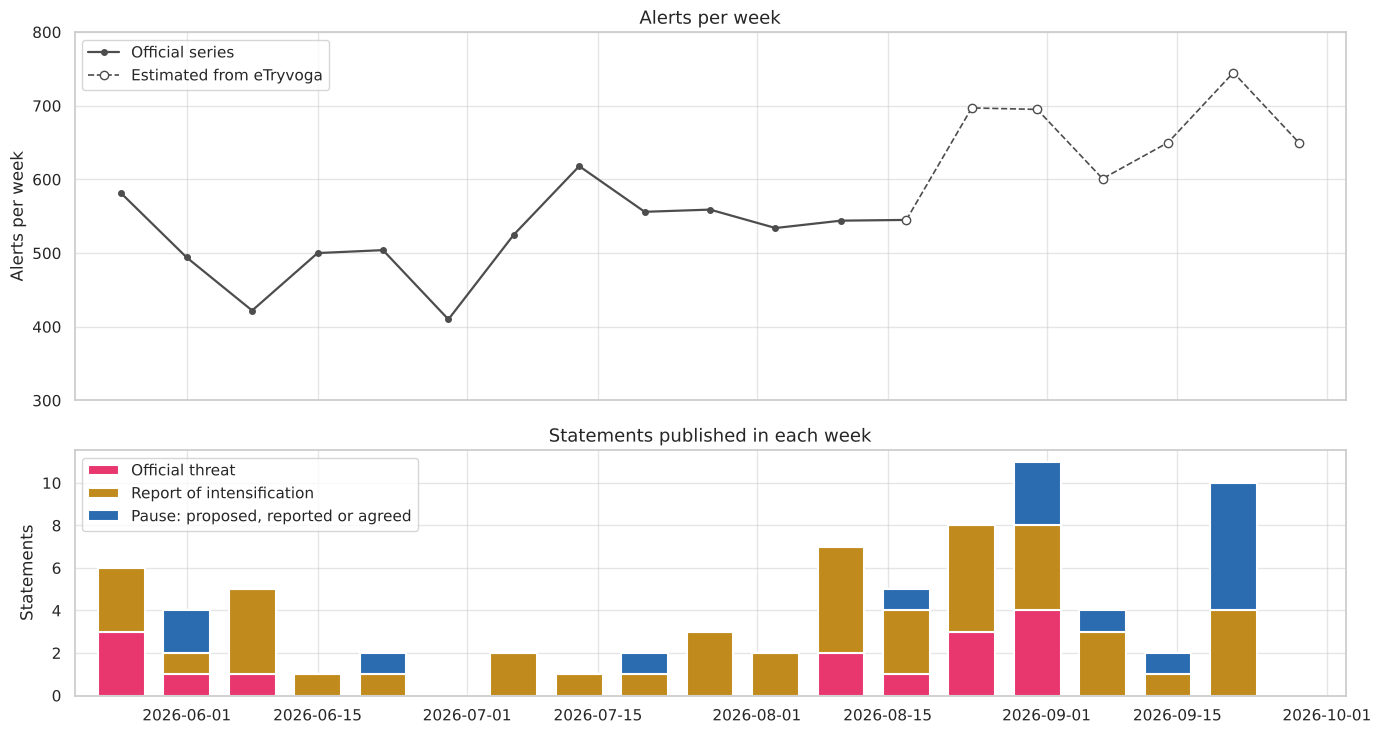

In [50]:
category_colours = {"official_threat": "#e8366f", "report_of_intensification": "#c08a1c", "pause": "#2b6cb0"}
category_labels = {"official_threat": "Official threat", "report_of_intensification": "Report of intensification",
                   "pause": "Pause: proposed, reported or agreed"}

published = (statements.groupby(["published_in_week", "category"]).size().unstack(fill_value=0)
             .reindex(columns=categories, fill_value=0))
window_start = news_targets[0] - pd.Timedelta(days=7)
published = published.reindex(pd.date_range(window_start, news_targets[-1], freq="W-MON"), fill_value=0)
shown = extended[window_start:]
official_part, estimated_part = shown[:weekly.index[-1]], shown[weekly.index[-1]:]

fig, axes = plt.subplots(2, 1, figsize=(14, 7.5), sharex=True, gridspec_kw={"height_ratios": [3, 2]})

axes[0].plot(official_part.index, official_part.values, color="0.3", linewidth=1.6, marker="o", markersize=4,
             label="Official series")
axes[0].plot(estimated_part.index, estimated_part.values, color="0.3", linewidth=1.2, linestyle="--", marker="o",
             markersize=6, markerfacecolor="white", label="Estimated from eTryvoga")
axes[0].set_title("Alerts per week", fontsize=13)
axes[0].set_ylabel("Alerts per week")
axes[0].set_ylim(300, 800)
axes[0].legend(loc="upper left", frameon=True)

bottom = np.zeros(len(published))
for category in categories:
    axes[1].bar(published.index, published[category], bottom=bottom, width=5, color=category_colours[category],
                edgecolor="white", linewidth=1.5, label=category_labels[category])
    bottom += published[category].to_numpy()
axes[1].set_title("Statements published in each week", fontsize=13)
axes[1].set_ylabel("Statements")
axes[1].yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
axes[1].legend(loc="upper left", frameon=True)

for ax in axes:
    ax.grid(alpha=0.5)
axes[1].set_xlim(window_start - pd.Timedelta(days=5), news_targets[-1] + pd.Timedelta(days=5))

plt.tight_layout()
plt.show()

**Reading.**

- **Reports of intensification** appear in almost every week, before the step as well as after it, so their presence singles out no week.
- **Official threats** are rarer and come in two clusters: from late May to mid-June, and from mid-August onwards.
- **Pauses** are mostly proposals. The only agreed pause in the air campaign itself is the three-day halt of strikes on Kyiv announced on 4 and 5 September; the two June items are local ceasefires around the Zaporizhzhia nuclear plant.

### Step 3. Do official threats lead the count?

We compare the plain model's errors (actual minus forecast) in the weeks that followed an official threat with its errors in the other weeks. If threats led the count, the first group would be higher.

The forecasts come from the model's own updating rule, written out so that step 4 can change it: each week the level moves towards the observed count by the correction fraction.

In [51]:
def weekly_updates(series, first_target):
    """For each week from the one before `first_target`: the correction fraction and the recent noise
    of ARIMA(0,1,1) fitted on the data up to and including that week."""
    start = series.index.get_loc(first_target) - 1
    updates = {}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for position in range(start, len(series)):
            fit = ARIMA(series.iloc[:position + 1], order=(0, 1, 1)).fit()
            updates[series.index[position]] = {
                "fraction": 1 + fit.params["ma.L1"],
                "noise": np.sqrt((fit.resid.iloc[-RECENT_WEEKS:] ** 2).mean()),
            }
        first_level = ARIMA(series.iloc[:start], order=(0, 1, 1)).fit().forecast(1).iloc[0]
    return pd.DataFrame(updates).T, first_level


def walk(series, updates, first_level, rule=None):
    """One-week-ahead forecasts. After each week the level moves by the model's fraction of the error,
    or all the way to the observed week when `rule(week, error, noise)` says the change is lasting."""
    level, forecasts, fired = first_level, {}, {}
    for week in updates.index:
        forecasts[week] = level
        error = series[week] - level
        fired[week] = bool(rule(week, error, updates.loc[week, "noise"])) if rule else False
        level = series[week] if fired[week] else level + updates.loc[week, "fraction"] * error
    # the first week is a warm-up, so that statements from the week before the first forecast can act
    return pd.Series(forecasts).iloc[1:], pd.Series(fired)


news_updates, news_first_level = weekly_updates(extended, news_targets[0])
plain_forecast, _ = walk(extended, news_updates, news_first_level)
plain_error = extended[news_targets] - plain_forecast

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    refitted = pd.Series({week: ARIMA(extended[:week].iloc[:-1], order=(0, 1, 1)).fit().forecast(1).iloc[0]
                          for week in news_targets})
print(f"largest difference from refitted ARIMA(0,1,1) forecasts: {(plain_forecast - refitted).abs().max():.1f} alerts")

after_threat = per_week["official_threat"] > 0
lead = pd.DataFrame({
    "weeks": [int(after_threat.sum()), int((~after_threat).sum())],
    "mean error (actual - forecast)": [plain_error[after_threat].mean(), plain_error[~after_threat].mean()],
    "weeks above the forecast": [int((plain_error[after_threat] > 0).sum()), int((plain_error[~after_threat] > 0).sum())],
}, index=["after a week with an official threat", "after a week without one"])

test = stats.mannwhitneyu(plain_error[after_threat], plain_error[~after_threat], alternative="greater")
print(f"Mann-Whitney test that errors are larger after a threat: p = {test.pvalue:.2f}")
print("errors after a threat, before the step: "
      + ", ".join(f"{value:+.0f}" for value in plain_error[after_threat].iloc[:int(after_threat.iloc[:n_before].sum())]))
lead.round(1)

largest difference from refitted ARIMA(0,1,1) forecasts: 1.2 alerts
Mann-Whitney test that errors are larger after a threat: p = 0.67
errors after a threat, before the step: -29, -89, +24, +1


,weeks,mean error (actual - forecast),weeks above the forecast
after a week with an official threat,7,15.8,4
after a week without one,11,23.3,8


**Reading.** No. Weeks after an official threat came in no higher against the forecast than other weeks. Of the four such weeks before the step, two were below the forecast, one slightly above and one on it.

Threats of this kind are a regular part of official language, so they do not say when the count will rise.

### Step 4. A threat as confirmation of a jump

The model sees when a week comes in high, but not whether the jump will last. Three rules take the same action, moving the level all the way to the week just observed. They differ in when they act:

- **News flag:** the week came in above the forecast, and an official threat was published during that week.
- **Numbers-only trigger** (control): the week came in above the forecast by more than twice the recent noise.
- **Every upward surprise** (control): the week came in above the forecast.

The two controls use no text, to show what the text adds.

In [52]:
threat_weeks = set(statements.loc[statements["category"] == "official_threat", "published_in_week"])

news_rules = {
    "Plain model": None,
    "News flag: official threat and a high week": lambda week, error, noise: week in threat_weeks and error > 0,
    "Numbers-only trigger: more than 2x noise above": lambda week, error, noise: error > 2 * noise,
    "Every upward surprise": lambda week, error, noise: error > 0,
}

news_forecasts, news_fired = {}, {}
for name, rule in news_rules.items():
    news_forecasts[name], news_fired[name] = walk(extended, news_updates, news_first_level, rule)
news_forecasts = pd.DataFrame(news_forecasts)
news_misses = news_forecasts.sub(extended[news_targets], axis=0).abs()
changed = news_forecasts.sub(news_forecasts["Plain model"], axis=0).abs() > 0.5

news_scores = pd.DataFrame({
    f"MAE, all {len(news_targets)} weeks": news_misses.mean(),
    f"MAE, {n_before} weeks before the step": news_misses.iloc[:n_before].mean(),
    f"MAE, {len(news_targets) - n_before} weeks from the step": news_misses.iloc[n_before:].mean(),
    "times the rule fired": {name: int(fired.iloc[:-1].sum()) for name, fired in news_fired.items()},
    "forecasts it changed": changed.sum(),
})
news_scores["MAE vs plain"] = news_scores.iloc[:, 0] / news_scores.iloc[0, 0]
news_scores.round(2)

,"MAE, all 18 weeks","MAE, 12 weeks before the step","MAE, 6 weeks from the step",times the rule fired,forecasts it changed,MAE vs plain
Plain model,52.18,40.94,74.66,0,0,1.00
News flag: official threat and a high week,52.05,45.67,64.83,3,16,1.00
Numbers-only trigger: more than 2x noise above,55.22,50.94,63.80,2,11,1.06
Every upward surprise,59.45,52.82,72.73,7,18,1.14


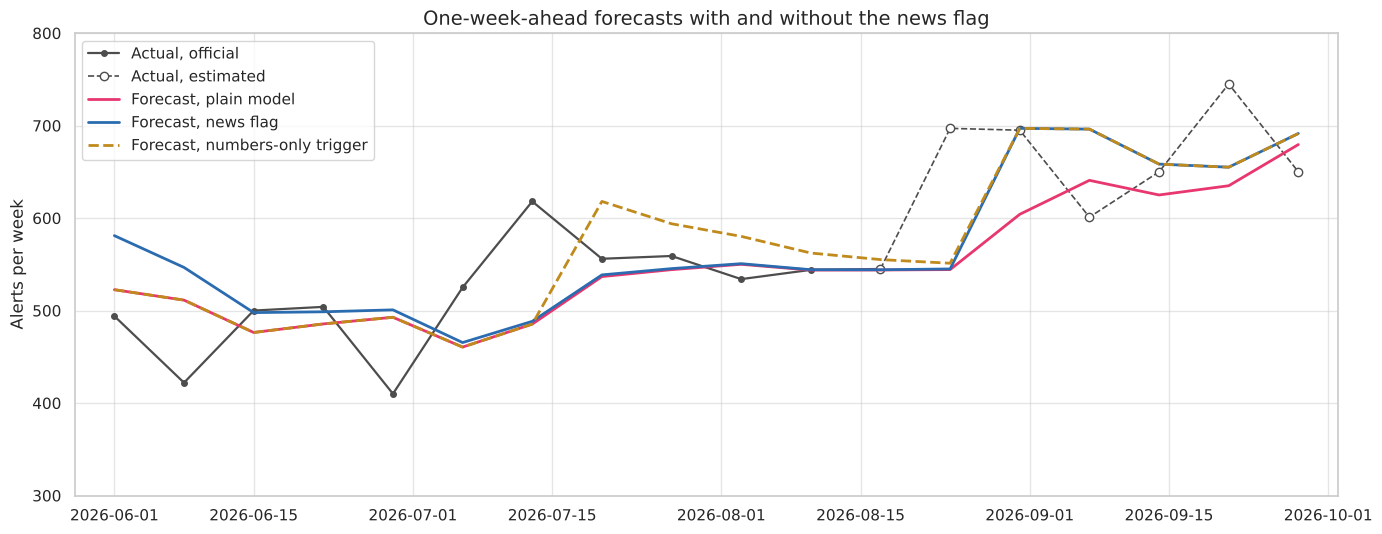

In [53]:
line_styles = {
    "Plain model": ("#e8366f", "-", "Forecast, plain model"),
    "News flag: official threat and a high week": ("#2b6cb0", "-", "Forecast, news flag"),
    "Numbers-only trigger: more than 2x noise above": ("#c08a1c", "--", "Forecast, numbers-only trigger"),
}
actual = extended[news_targets]

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(actual[:weekly.index[-1]].index, actual[:weekly.index[-1]].values, color="0.3", linewidth=1.6, marker="o",
        markersize=4, label="Actual, official")
ax.plot(actual[weekly.index[-1]:].index, actual[weekly.index[-1]:].values, color="0.3", linewidth=1.2, linestyle="--",
        marker="o", markersize=6, markerfacecolor="white", label="Actual, estimated")
for name, (colour, style, label) in line_styles.items():
    ax.plot(news_forecasts.index, news_forecasts[name], color=colour, linewidth=2, linestyle=style, label=label)

ax.set_title("One-week-ahead forecasts with and without the news flag", fontsize=14)
ax.set_ylabel("Alerts per week")
ax.set_ylim(300, 800)
ax.set_xlim(news_targets[0] - pd.Timedelta(days=4), news_targets[-1] + pd.Timedelta(days=4))
ax.grid(alpha=0.5)
ax.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()

**Reading.**

- **The news flag was wrong once and right once, and the two cancel out.** Over all 18 weeks it has practically the same average miss as the plain model.
  - *Wrong:* after the week of 25 May it moved the level up, and the next two weeks fell back.
  - *Right:* after the week of 24 August it moved the level up again, and the count stayed there.
- **The good firing gave part of its gain back.** The week of 7 September came in low, after an announced three-day pause of strikes on Kyiv, which the rule cannot use.
- **The numbers-only trigger is worse than the plain model.** It caught the August jump, but it had also jumped at one high week in July.
- **Moving on every upward surprise is the worst rule.**

### Step 5. What the numbers-only trigger costs over two years

The trigger needs no text, so it can be run over the 104 test weeks of section 6 followed by the six estimated weeks. This shows how often it fires when it has only the size of the surprise to go on.

In [54]:
long_updates, long_first_level = weekly_updates(extended, recheck_actual.index[0])
long_actual = extended[recheck_actual.index[0]:]

long_plain, _ = walk(extended, long_updates, long_first_level)
long_trigger, long_fired = walk(extended, long_updates, long_first_level, news_rules["Numbers-only trigger: more than 2x noise above"])
long_misses = pd.DataFrame({"Plain model": (long_plain - long_actual).abs(),
                            "Numbers-only trigger": (long_trigger - long_actual).abs()})
official_weeks = long_misses.index <= weekly.index[-1]

long_scores = pd.DataFrame({
    f"MAE, {int(official_weeks.sum())} official weeks": long_misses[official_weeks].mean(),
    f"MAE, {int((~official_weeks).sum())} weeks from the step": long_misses[~official_weeks].mean(),
    "MAE, all weeks": long_misses.mean(),
})
print(f"the trigger fired {int(long_fired.iloc[1:].sum())} times in {len(long_actual)} weeks, in the weeks starting: "
      + ", ".join(f"{week:%d %b %Y}" for week in long_fired.iloc[1:][long_fired.iloc[1:]].index))
difference = long_misses.loc[official_weeks, "Numbers-only trigger"] - long_misses.loc[official_weeks, "Plain model"]
print(f"paired test on the official weeks, trigger against plain: p = {stats.ttest_1samp(difference, 0).pvalue:.2f}")
long_scores.round(1)

the trigger fired 4 times in 110 weeks, in the weeks starting: 30 Dec 2024, 30 Mar 2026, 13 Jul 2026, 24 Aug 2026
paired test on the official weeks, trigger against plain: p = 0.01


,"MAE, 104 official weeks","MAE, 6 weeks from the step","MAE, all weeks"
Plain model,36.5,74.7,38.6
Numbers-only trigger,40.5,63.8,41.8


**Reading.** The trigger fires only a handful of times in two years, and still it makes the forecasts worse in ordinary weeks: most large surprises are single weeks that fall back. Any flag, built on numbers or on text, has to beat this false-alarm cost before it is worth using.

### What the experiment shows

- **News did not predict the step.** Similar threats in May, June and mid-August were followed by nothing.
- **News did not confirm a step reliably.** A high week with a threat was followed by a lasting rise once and by a fall back once.
- **The forecasts in sections 7 to 9 stay as they are.**

### What might still work

- **Finer coding:** separating threats of retaliation from announcements of a campaign.
- **Pauses:** the one agreed pause was followed by the lowest week after the step.
- **More weeks:** 18 weeks contain one step; two years would contain more.

### Limits of the experiment

- **Hindsight:** the rules were chosen knowing about the August step.
- **Two filters:** digest editors and a language model selected the statements, so some were missed.
- **Dates to the day:** a statement dated on a Sunday counts as published before that Sunday's forecast.
- **Estimated weeks:** the six weeks from the step carry a conversion error as large as the differences between the rules.

## 11. Conclusions: which series answers which question

**The path of the analysis.**

1. Count the alerts and forecast them (sections 1 to 8).
2. Notice that the trend of the count is flatter than expected (section 3).
3. Measure time under alert and repeat the analysis (section 9).
4. Test whether news can make up for the forecast's one clear failure (section 10).

Each series answers one question:

- **How many alerts will there be next week?** The count of alerts.
- **How did the pressure on the country change over the war?** The hours under alert, because alerts grew longer and wider much more than they grew more frequent.

The table puts the two side by side.

In [55]:
def growth(column):
    return per_year.loc[last_year, column] / per_year.loc[first_year, column]


def first_week(frame, digits):
    row = frame.iloc[0]
    return (f"{row['forecast']:.{digits}f} ({row['95% low']:.{digits}f} to {row['95% high']:.{digits}f}), "
            f"week of {frame.index[0]:%d %b %Y}")


count_summary, hours_summary = decomposition_summary(parts), decomposition_summary(hours_parts)

conclusions = pd.DataFrame({
    "count of alerts": {
        "question it answers": "how many alerts next week",
        f"growth of the weekly average, {first_year} to {last_year}": f"x{growth('alerts'):.2f}",
        "trend strength (0 to 1)": f"{count_summary['trend strength']:.2f}",
        "remainder, share of variance": f"{count_summary['remainder, share of variance']:.0%}",
        "stationary without differencing": stationarity.loc["series, around a constant", "verdict"],
        "forecasting model": "ARIMA(0,1,1)",
        f"MAE, 1 week ahead, {RECHECK_WEEKS} test weeks": f"{recheck.loc['ARIMA(0,1,1)', 'MAE']:.1f} alerts",
        "MASE (below 1 beats the naive forecast)": f"{recheck.loc['ARIMA(0,1,1)', 'MASE']:.2f}",
        "95% interval coverage, 1 week ahead": f"{by_horizon.loc[1, '95%, recent noise']:.0%}",
        "forecast from official data (95% interval)": first_week(forecast, 0),
        "forecast including estimated weeks (95% interval)": first_week(updated_forecast, 0),
    },
    "hours under alert": {
        "question it answers": "how the pressure changed over the war",
        f"growth of the weekly average, {first_year} to {last_year}": f"x{growth('alert_hours'):.2f}",
        "trend strength (0 to 1)": f"{hours_summary['trend strength']:.2f}",
        "remainder, share of variance": f"{hours_summary['remainder, share of variance']:.0%}",
        "stationary without differencing": hours_stationarity.loc["series, around a constant", "verdict"],
        "forecasting model": "ARIMA(1,1,1)",
        f"MAE, 1 week ahead, {RECHECK_WEEKS} test weeks": f"{hours_scores.loc['ARIMA(1,1,1)', 'MAE']:.1f} hours",
        "MASE (below 1 beats the naive forecast)": f"{hours_scores.loc['ARIMA(1,1,1)', 'MASE']:.2f}",
        "95% interval coverage, 1 week ahead": f"{hours_by_horizon.loc[1, '95% interval coverage']:.0%}",
        "forecast from official data (95% interval)": first_week(hours_forecast, 1),
        "forecast including estimated weeks (95% interval)": "not available (section 9, limits)",
    },
})
conclusions

,count of alerts,hours under alert
question it answers,how many alerts next week,how the pressure changed over the war
"growth of the weekly average, 2023 to 2026",x1.45,x2.53
trend strength (0 to 1),0.59,0.87
"remainder, share of variance",33%,13%
stationary without differencing,tests disagree,not stationary
forecasting model,"ARIMA(0,1,1)","ARIMA(1,1,1)"
"MAE, 1 week ahead, 104 test weeks",36.5 alerts,3.8 hours
MASE (below 1 beats the naive forecast),0.78,0.84
"95% interval coverage, 1 week ahead",93%,93%
forecast from official data (95% interval),"544 (443 to 646), week of 24 Aug 2026","39.5 (29.6 to 49.3), week of 24 Aug 2026"


### The two trends on one scale

Each trend is divided by its own average over the first full year of the log and multiplied by 100, so 200 means twice that year's level. The faint lines are the weekly values on the same scale.

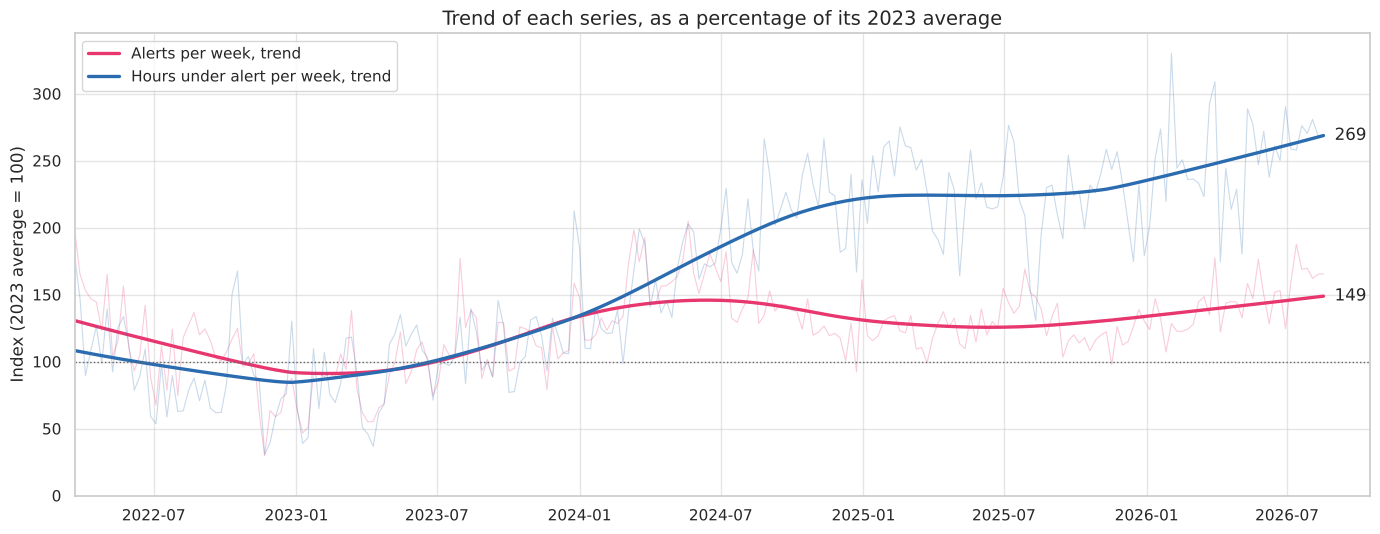

latest trend value as a percentage of the base-year average:
Alerts per week               149
Hours under alert per week    269


In [56]:
base = weekly.index.year == first_year
indexed_trend = pd.DataFrame({
    "Alerts per week": parts["trend"] / weekly[base].mean() * 100,
    "Hours under alert per week": hours_parts["trend"] / hours[base].mean() * 100,
})
indexed_weekly = pd.DataFrame({
    "Alerts per week": weekly / weekly[base].mean() * 100,
    "Hours under alert per week": hours / hours[base].mean() * 100,
})
colours = {"Alerts per week": "#e8366f", "Hours under alert per week": "#2b6cb0"}

fig, ax = plt.subplots(figsize=(14, 5.5))

for name, colour in colours.items():
    ax.plot(indexed_weekly.index, indexed_weekly[name], color=colour, linewidth=0.8, alpha=0.25)
    ax.plot(indexed_trend.index, indexed_trend[name], color=colour, linewidth=2.4, label=f"{name}, trend")
    ax.annotate(f"{indexed_trend[name].iloc[-1]:.0f}", (indexed_trend.index[-1], indexed_trend[name].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=12, color="0.15")
ax.axhline(100, color="0.4", linewidth=1, linestyle=":")

ax.set_title(f"Trend of each series, as a percentage of its {first_year} average", fontsize=14)
ax.set_ylabel(f"Index ({first_year} average = 100)")
ax.set_xlim(weekly.index.min(), weekly.index.max() + pd.Timedelta(days=60))
ax.set_ylim(0, None)
ax.grid(alpha=0.5)
ax.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()

print("latest trend value as a percentage of the base-year average:")
print(indexed_trend.iloc[-1].round(0).astype(int).to_string())

### What the analysis establishes

- **The threat grew through time under alert, not through the number of alerts.** The count stayed in a band, while hours per district more than doubled.
- **The count is a slowly moving level plus noise.** Best model: ARIMA(0,1,1). Fourteen others do no better.
- **The hours series is mostly trend.** Best model: ARIMA(1,1,1).
- **Both models beat the naive forecast by a modest margin,** and their 95% intervals held on weeks they had not seen.
- **Neither news nor a yearly pattern improved any forecast.**

### Which figure to use for what

- **Alerts in the coming weeks:** the forecast that includes the estimated weeks (section 8).
- **A forecast from official data only:** the section 7 forecast, overtaken by the rise after 23 August 2026.
- **How much the war intensified:** hours under alert (section 9, step 1).
- **Comparison with published statistics:** the `regional_alerts` column.

### Limits that remain

- **A change of level cannot be forecast from the series itself.** The forecast made a week before the August 2026 step missed it.
- **The official log ends on 7 September 2026.** The latest weeks of the count are estimates, and the hours series cannot be extended.
- **Hours under alert is an average over districts,** so it hides the difference between front-line and rear regions.